# The complete study on the September 2026 snapshot, with v1 as the baseline
One notebook, one data set (SPX options pulled 30 September 2026 at 15:22 EDT, spot 7,696.50), every analysis of the project. The baseline is **v1 exactly as submitted in December 2025**, imported verbatim from `original_submission/heston_pricer.py`: the v1 expiry rule without any quote filter, the price-RMSE calibration (differential evolution then L-BFGS-B), Euler full-truncation Monte Carlo with one flat drift $r(T)-q(T)$, no payment lag, and the pricing date taken from the clock as v1 did (here the snapshot time, so day counts floor as v1's did). Everything else is layered on those parameters and conventions so every table is comparable with the submission.

Sections: 1 data · 2 v1 calibration · 3 v1 Monte Carlo · 4 validation suite · 5 PDE benchmark and Greeks · 6 sensitivity scans · 7 price attribution and rates · 8 calibration objectives · 9 optimisers · 10 models · 11 Feller · 12 engines and vol inversion · 13 expiry rule · 14 Monte Carlo methods · 15 vol surfaces · 16 LV, Heston, LSV · 17 fact table · 18 conclusions.


In [1]:
import sys, os, time, importlib.util, contextlib, io, numpy as np, pandas as pd
from datetime import datetime, timedelta
from scipy.optimize import differential_evolution, minimize
from scipy import optimize, stats
import matplotlib.pyplot as plt
import matplotlib.transforms as transforms
pd.set_option('display.width', 220); pd.set_option('display.max_colwidth', 60)

# v1 code, verbatim
spec = importlib.util.spec_from_file_location("heston_v1", "original_submission/heston_pricer.py"); v1 = importlib.util.module_from_spec(spec); spec.loader.exec_module(v1)
# v2 and methods modules (checks, alternatives, PDE)
import heston_pricer as hp
from heston_pricer import (rate_curve_func, set_rate_curve, attach_quote_details, filter_call_spread_arbitrage, implied_vol_call_vec, bs_vega, bs_call_price,
                           HestonAutocallPricer, heston_engine_qe_numba, heston_engine_euler_numba, suppress_stdout)
from vol_models import HestonModel, BatesModel, DoubleHestonModel, RoughHestonModel, FFTCalibrator, MultiModelPricer
from methods import *
from pde_heston import HestonADISolver, price_autocall_pde, log_spot_grid, variance_grid

def quiet(fn, *a, **k):
    with contextlib.redirect_stdout(io.StringIO()): return fn(*a, **k)

DATA_FILE = "calibration_data_September_30_2026.xlsx"
_spot = pd.read_excel(DATA_FILE, sheet_name="Spot Price"); S0 = float(_spot['S0'].iloc[0])
PRICING_DATE = pd.to_datetime(_spot['Date'].iloc[0]).to_pydatetime()          # v1 used datetime.now(): the snapshot clock
_rates = pd.read_excel(DATA_FILE, sheet_name="Rates"); set_rate_curve(list(zip(_rates['tenor_years'], _rates['rate_pct'])), coupon_freq=2)
RATE_SOURCE = f"{_rates['source'].iloc[0]}, as of {_rates['as_of'].iloc[-1]}"
clean = pd.read_excel(DATA_FILE, sheet_name="Cleaned Data")

TD = timedelta(days=183); sched = [PRICING_DATE + 2 * TD]
for _ in range(6): sched.append(sched[-1] + TD)
SCHEDULE = [d.strftime("%Y-%m-%d") for d in sched]
OBS = np.array([(datetime.strptime(d, "%Y-%m-%d") - PRICING_DATE).days / 365 for d in SCHEDULE]); T_MAX = OBS[-1]
PRODUCT_V1 = {"full_schedule": SCHEDULE, "coupon_step": 0.03, "barrier_redemption": 0.70, "barrier_knock_in": 0.60, "exit_bonus": 0.24, "nominal": 1000}

# v1 expiry rule, no filter
targets = sorted(set([0.08, 0.25, 0.5, 1.0, 1.5, 2.0, 3.0, 4.0] + list(OBS)))
avail = np.sort(clean['T'].unique()); sel = []
for t in targets:
    c = avail[np.abs(avail - t).argmin()]
    if c not in sel: sel.append(c)
df_v1 = clean[clean['T'].isin(sel)].reset_index(drop=True)
df_v1 = attach_quote_details(df_v1, DATA_FILE, rate_curve_func)      # bid/ask and trade dates for weights and liquidity stats; no rows removed
q_data = df_v1[['T', 'implied_q']].groupby('T').mean().sort_index()
q_func = lambda T: np.interp(T, q_data.index.values, q_data['implied_q'].values)
MU_FLAT = float(rate_curve_func(T_MAX)) - float(q_func(T_MAX))          # v1's single drift for the whole path
q_eff = lambda t: rate_curve_func(t) - MU_FLAT                          # gives the v2 tools v1's flat forward
SHORT_T = 0.4
_kept, _ = filter_call_spread_arbitrage(df_v1, rate_curve_func)
_key = lambda d: list(zip(d['T'].round(6), d['strike'].round(2), d['type_before_conversion']))
CLEAN_KEYS = set(_key(_kept)); df_v1['clean'] = [k in CLEAN_KEYS for k in _key(df_v1)]
print(f"Snapshot {PRICING_DATE} | spot {S0:.2f} | {RATE_SOURCE}")
print(f"Schedule {SCHEDULE} | observation times {np.round(OBS, 4)} | flat drift r(T)-q(T) = {100*MU_FLAT:.3f}%")
print(f"v1 selection: expiries {np.round(sel, 3)}, {len(df_v1)} quotes, no filter")


Snapshot 2026-09-30 15:22:50.029000 | spot 7696.50 | FRED Treasury constant-maturity yield (proxy for SOFR OIS), as of 2026-09-28
Schedule ['2027-10-01', '2028-04-01', '2028-10-01', '2029-04-02', '2029-10-02', '2030-04-03', '2030-10-03'] | observation times [1.     1.5014 2.0027 2.5041 3.0055 3.5068 4.0082] | flat drift r(T)-q(T) = 4.482%
v1 selection: expiries [0.088 0.249 0.496 0.997 1.307 2.208 3.225 4.222], 1360 quotes, no filter


## 1. Data: liquidity by expiry, implied dividends, rates

In [2]:
r_ = np.asarray(rate_curve_func(df_v1['T'].values)); iv_b = implied_vol_call_vec(df_v1['bid_call_eq'], S0, df_v1['strike'], df_v1['T'], r_, df_v1['implied_q']); iv_a = implied_vol_call_vec(df_v1['ask_call_eq'], S0, df_v1['strike'], df_v1['T'], r_, df_v1['implied_q'])
d_ = df_v1.assign(spread_pts=df_v1['ask'] - df_v1['bid'], vol_spread=100 * (iv_a - iv_b), traded_today=df_v1['lastTradeDate'].dt.normalize() == pd.Timestamp(PRICING_DATE).normalize())
g = d_.groupby('T')
liq = pd.DataFrame({'quotes': g.size(), 'traded today %': (100 * g['traded_today'].mean()).round(0), 'median age (days)': g['quote_age_days'].median(), 'volume': g['volume'].sum(), 'open interest': g['openInterest'].sum().astype(int),
                    'median spread (pts)': g['spread_pts'].median().round(2), 'median spread (vol pts)': g['vol_spread'].median().round(2), 'implied dividend %': (100 * g['implied_q'].first()).round(3), 'min K/S0': (g['strike'].min() / S0).round(2), 'max K/S0': (g['strike'].max() / S0).round(2)})
display(liq)
print("Zero-rate curve:", ", ".join(f"{t}y {100*float(rate_curve_func(t)):.3f}%" for t in [0.25, 0.5, 1, 2, 3, 4]))
print(f"Implied dividends all positive: {bool((df_v1['implied_q'] > 0).all())}; range {100*df_v1['implied_q'].min():.2f}% to {100*df_v1['implied_q'].max():.2f}%")


,quotes,traded today %,median age (days),volume,open interest,median spread (pts),median spread (vol pts),implied dividend %,min K/S0,max K/S0
T,,,,,,,,,,
0.087671,50,68.0,0.0,1195,5652,0.5,0.09,0.344,0.60,1.12
0.249315,553,28.0,2.0,19734,818153,0.4,0.05,0.609,0.45,1.25
0.495890,403,19.0,6.0,6979,83484,0.5,0.04,0.550,0.45,1.25
0.997260,84,37.0,1.0,2025,3187,1.0,0.04,0.377,0.69,1.25
1.306849,60,42.0,1.0,3124,6512,1.8,0.07,0.348,0.52,1.25
2.208219,104,15.0,6.0,9424,223426,4.6,0.15,0.523,0.45,1.25
3.224658,59,17.0,8.0,1376,117963,21.7,0.65,0.516,0.45,1.25
4.221918,47,2.0,19.0,1455,61841,133.0,4.14,0.500,0.45,1.25


Zero-rate curve: 0.25y 4.257%, 0.5y 4.362%, 1y 4.488%, 2y 4.875%, 3y 4.961%, 4y 4.986%
Implied dividends all positive: True; range 0.34% to 0.61%


## 2. The v1 calibration on the September quotes (price RMSE, DE + L-BFGS-B, v1 code)

In [3]:
cal_v1 = v1.HestonFFTCalibrator(df_v1, S0, rate_curve_func)
t0 = time.perf_counter()
rg = differential_evolution(cal_v1.objective_function, bounds=cal_v1.bounds, strategy='best1bin', maxiter=50, popsize=15, tol=1e-4, seed=42)
rl = minimize(cal_v1.objective_function, x0=rg.x, method='L-BFGS-B', bounds=cal_v1.bounds, tol=1e-6)
PARAMS_V1 = rl.x; V1_SECS = time.perf_counter() - t0
print(f"v1 parameters: kappa {PARAMS_V1[0]:.4f}, theta {PARAMS_V1[1]:.4f}, sigma {PARAMS_V1[2]:.4f}, rho {PARAMS_V1[3]:.4f}, v0 {PARAMS_V1[4]:.4f}; price RMSE {rl.fun:.4f} ({V1_SECS:.0f} s)")
print(f"spot vol {100*np.sqrt(PARAMS_V1[4]):.2f}%, long-run vol {100*np.sqrt(PARAMS_V1[1]):.2f}%, half-life {12*np.log(2)/PARAMS_V1[0]:.1f} months; Feller 2 kappa theta = {2*PARAMS_V1[0]*PARAMS_V1[1]:.4f} vs sigma^2 = {PARAMS_V1[2]**2:.4f} (ratio {2*PARAMS_V1[0]*PARAMS_V1[1]/PARAMS_V1[2]**2:.3f})")
cal_iv = FFTCalibrator(df_v1, S0, rate_curve_func, model=HestonModel(), objective='iv')      # same quotes, vol metrics and spread weights

def score(params, c=None, label=''):
    c = cal_iv if c is None else c
    sp = c.error_split(params, SHORT_T); px = c.price_surface(params)
    is_put = (c.market_data['type_before_conversion'] == 'put').values; otm = c.market_data['mid_price'].values
    shift = S0 * np.exp(-c.flat_q * c.flat_T) - c.flat_K * np.exp(-c.flat_r * c.flat_T)
    rel = (np.where(is_put, px - shift, px) - otm) / otm
    errs = []; errs_clean = []
    clean_flag = c.market_data['clean'].values if 'clean' in c.market_data.columns else np.ones(len(c.flat_K), bool)
    for b in c.data_batches:
        if b['T'] < 0.9: continue
        rT = c.r_curve(b['T']); m = c.flat_T == b['T']; cf = clean_flag[m]
        for mon in [0.6, 0.7, 0.8, 0.9, 1.0]:
            for use_clean, store in [(False, errs), (True, errs_clean)]:
                ks = b['strikes'][cf] if use_clean else b['strikes']; mk = c.market_iv[m][cf] if use_clean else c.market_iv[m]
                if len(ks) == 0: continue
                j = np.argmin(np.abs(ks - mon * S0)); K = ks[j]
                store.append(100 * abs(implied_vol_call_vec(c.price_calls(params, b['T'], [K], b['q']), S0, K, b['T'], rT, b['q'])[0] - mk[j]))
    return {'label': label, 'vol RMSE all': sp['all']['IV RMSE'], 'vol RMSE 1M-3M': sp['short (<6M)']['IV RMSE'], 'vol RMSE 6M+': sp['6M+']['IV RMSE'], 'max |vol err|': sp['all']['max |IV err|'],
            'price RMSE': sp['all']['price RMSE'], 'price RMSE 6M+': sp['6M+']['price RMSE'], 'price RMSE % of spot': 100 * sp['all']['price RMSE'] / S0,
            'rel. price RMSE OTM %': 100 * np.sqrt(np.mean(rel**2)), 'median |rel| %': 100 * np.median(np.abs(rel)), 'product strikes': float(np.mean(errs)), 'product strikes (clean quotes)': float(np.mean(errs_clean))}
FIT_V1 = score(PARAMS_V1, label='v1 Heston (price objective)')
display(pd.DataFrame([FIT_V1]).set_index('label').round(3))
rep = cal_iv.fit_report(PARAMS_V1); display(rep[['T', 'n', 'IV RMSE (vol pts)', 'price RMSE', 'max |IV err| (vol pts)']].round(3))


v1 parameters: kappa 1.7026, theta 0.0543, sigma 1.0212, rho -0.6230, v0 0.0252; price RMSE 20.8104 (21 s)
spot vol 15.88%, long-run vol 23.30%, half-life 4.9 months; Feller 2 kappa theta = 0.1849 vs sigma^2 = 1.0429 (ratio 0.177)


,vol RMSE all,vol RMSE 1M-3M,vol RMSE 6M+,max |vol err|,price RMSE,price RMSE 6M+,price RMSE % of spot,rel. price RMSE OTM %,median |rel| %,product strikes,product strikes (clean quotes)
label,,,,,,,,,,,
v1 Heston (price objective),1.663,2.238,0.988,19.045,20.81,27.396,0.27,23.979,4.747,0.421,0.232


,T,n,IV RMSE (vol pts),price RMSE,max |IV err| (vol pts)
0,0.087671,50,4.172,9.959,19.045
1,0.249315,553,1.972,5.353,12.945
2,0.49589,403,1.056,5.838,6.780
3,0.99726,84,0.546,15.283,0.811
4,1.306849,60,0.514,15.346,1.236
5,2.208219,104,0.413,7.904,2.680
6,3.224658,59,1.024,14.616,6.610
7,4.221918,47,1.899,103.305,9.449
8,ALL,1360,1.663,20.810,19.045


## 3. The v1 Monte Carlo (Euler full truncation, flat drift, no payment lag, 50,000 paths, seed 42)

In [4]:
pricer_v1 = v1.HestonAutocallPricer(S0, S0, rate_curve_func, q_func, PARAMS_V1)
np.random.seed(42); quiet(pricer_v1.run_simulation, T_max=T_MAX, steps_per_year=252, n_paths=50000)
price, p_principal, p_coupon, p_put = quiet(pricer_v1.price_structure, **PRODUCT_V1, pricing_date=PRICING_DATE)
S = pricer_v1.S_paths; n = S.shape[1]; idxs = [pricer_v1._get_time_index(t) for t in OBS]
active = np.ones(n, bool); pv = np.zeros(n); calls = []
for k, (t, i) in enumerate(zip(OBS[:-1], idxs[:-1])):
    c_ = active & (S[i] >= S0); df = np.exp(-rate_curve_func(t) * t); pv[c_] = 1000 * (1 + (k + 2) * 0.03) * df; active[c_] = False; calls.append(c_.mean())
ST = S[idxs[-1]]; dfT = np.exp(-rate_curve_func(T_MAX) * T_MAX)
bonus = active & (ST >= 0.7 * S0); par = active & (ST >= 0.6 * S0) & (ST < 0.7 * S0); ki = active & (ST < 0.6 * S0)
pv[bonus] = 1240 * dfT; pv[par] = 1000 * dfT; pv[ki] = 1000 * ST[ki] / S0 * dfT
MC_SE = pv.std(ddof=1) / np.sqrt(n); assert abs(pv.mean() - price) < 1e-6
OUT_V1 = {'price': price, 's.e.': MC_SE, 'principal': p_principal, 'coupons': p_coupon, 'put': p_put, 'P(call) by date': np.round(calls, 4), 'P(call any)': sum(calls),
          'P(bonus)': bonus.mean(), 'P(par)': par.mean(), 'P(KI)': ki.mean(), 'E[level|KI]': ST[ki].mean() / S0, 'expected loss': ki.mean() * (1 - ST[ki].mean() / S0), 'life': pricer_v1.expected_life}
print(f"Fair value {price:.2f} = {price/10:.2f}% of par (s.e. {MC_SE:.2f}); principal {p_principal:.2f}, coupons {p_coupon:.2f}, put {p_put:.2f}")
print(f"autocall by date {np.round(calls, 3)} (total {sum(calls):.1%}); bonus {bonus.mean():.1%}, par {par.mean():.1%}, knock-in {ki.mean():.1%}; mean level given KI {ST[ki].mean()/S0:.1%}; expected loss {OUT_V1['expected loss']:.2%}; expected life {pricer_v1.expected_life:.2f} y")
# fair coupon on the same paths (bisection on coupon, bonus = 8 x coupon)
def px_c(c): return quiet(pricer_v1.price_structure, **{**PRODUCT_V1, 'coupon_step': c, 'exit_bonus': 8 * c}, pricing_date=PRICING_DATE)[0]
C_PAR = optimize.brentq(lambda c: px_c(c) - 1000, 0.0, 0.2); C_MARGIN = optimize.brentq(lambda c: px_c(c) - 987.5, 0.0, 0.2)
print(f"fair coupon per semester at par {C_PAR:.3%}, at 98.75% {C_MARGIN:.3%}")


Fair value 975.84 = 97.58% of par (s.e. 0.71); principal 930.55, coupons 70.94, put -25.66
autocall by date [0.71  0.074 0.038 0.023 0.017 0.013] (total 87.5%); bonus 6.1%, par 1.5%, knock-in 5.0%; mean level given KI 37.1%; expected loss 3.13%; expected life 1.55 y
fair coupon per semester at par 4.022%, at 98.75% 3.493%


## 4. Validation suite on the v1 paths

In [5]:
F = lambda t: S0 * np.exp(MU_FLAT * t)
rows = []
for t in [0.25, 1.0, 2.0, 3.0, T_MAX]:
    i = pricer_v1._get_time_index(t); tg = pricer_v1.time_grid[i]; ratio = S[i] / F(tg)
    rows.append({'T': round(tg, 3), 'E[S_t]/F(t) - 1': ratio.mean() - 1, 's.e.': ratio.std(ddof=1) / np.sqrt(n)})
print("Martingale check:"); display(pd.DataFrame(rows).round(5))
rows = []
for t in [OBS[0], T_MAX]:
    i = pricer_v1._get_time_index(t); tg = pricer_v1.time_grid[i]; K = np.array([0.6, 0.7, 0.8, 0.9, 1.0, 1.1]) * S0
    dfc = np.exp(-rate_curve_func(tg) * tg); pay = np.maximum(S[i][None, :] - K[:, None], 0) * dfc
    mc = pay.mean(1); se_ = pay.std(1, ddof=1) / np.sqrt(n); fft = cal_iv.price_calls(PARAMS_V1, tg, K, q_eff(tg))
    for k_, m_, s_, f_ in zip(K / S0, mc, se_, fft): rows.append({'T': round(tg, 3), 'K/S0': k_, 'MC': m_, 'FFT': f_, '(MC-FFT)/s.e.': (m_ - f_) / s_})
van = pd.DataFrame(rows); VAN_MAX = van['(MC-FFT)/s.e.'].abs().max(); print(f"Vanilla repricing MC vs FFT (largest |gap| {VAN_MAX:.2f} s.e.):"); display(van.round(3))
rows = []
for spy in [12, 52, 252]:
    p2 = v1.HestonAutocallPricer(S0, S0, rate_curve_func, q_func, PARAMS_V1); np.random.seed(42); quiet(p2.run_simulation, T_max=T_MAX, steps_per_year=spy, n_paths=50000)
    rows.append({'steps per year': spy, 'price': quiet(p2.price_structure, **PRODUCT_V1, pricing_date=PRICING_DATE)[0]})
STEP_CONV = pd.DataFrame(rows); print("Step-size convergence (Euler):"); display(STEP_CONV.round(2))
rows = []
for n_p in [25000, 50000, 100000, 200000]:
    p2 = v1.HestonAutocallPricer(S0, S0, rate_curve_func, q_func, PARAMS_V1); np.random.seed(42); quiet(p2.run_simulation, T_max=T_MAX, steps_per_year=252, n_paths=n_p)
    rows.append({'paths': n_p, 'price': quiet(p2.price_structure, **PRODUCT_V1, pricing_date=PRICING_DATE)[0]}); del p2
PATH_CONV = pd.DataFrame(rows); print("Path convergence:"); display(PATH_CONV.round(2))
K = 0.7 * S0; h = 0.002; c = cal_iv.price_calls(PARAMS_V1, T_MAX, [K * (1 - h), K * (1 + h)], q_eff(T_MAX)); DIGITAL = (c[0] - c[1]) / (2 * h * K) / dfT
CLOSED = 1000 * dfT * (1 + 0.24 * DIGITAL)
LIM_MC = quiet(pricer_v1.price_structure, full_schedule=[SCHEDULE[-1]], coupon_step=0.03, barrier_redemption=0.7, barrier_knock_in=0.0, exit_bonus=0.24, nominal=1000, pricing_date=PRICING_DATE)[0]
BOND_MC = quiet(pricer_v1.price_structure, full_schedule=[SCHEDULE[-1]], coupon_step=0.0, barrier_redemption=0.7, barrier_knock_in=0.0, exit_bonus=0.0, nominal=1000, pricing_date=PRICING_DATE)[0]
print(f"Limit case (no autocall, KI = 0): MC {LIM_MC:.2f} vs closed form bond + digital {CLOSED:.2f}  [P(S_T >= 70%): FFT {DIGITAL:.4f}, MC {(ST >= 0.7*S0).mean():.4f}]")
print(f"Pure bond: MC {BOND_MC:.4f} vs 1000 x DF {1000*dfT:.4f}")


Martingale check:


,T,E[S_t]/F(t) - 1,s.e.
0,0.254,-0.00014,0.00037
1,1.003,-0.00090,0.00078
2,2.002,-0.00227,0.00114
3,3.001,-0.00306,0.00142
4,4.008,-0.00225,0.00167


Vanilla repricing MC vs FFT (largest |gap| 1.56 s.e.):


,T,K/S0,MC,FFT,(MC-FFT)/s.e.
0,1.003,0.6,3308.012,3314.487,-1.169
1,1.003,0.7,2602.303,2608.610,-1.210
2,1.003,0.8,1917.511,1923.620,-1.284
3,1.003,0.9,1269.426,1274.870,-1.314
4,1.003,1.0,690.874,696.105,-1.561
5,1.003,1.1,266.743,269.752,-1.249
6,4.008,0.6,3885.289,3899.672,-1.259
7,4.008,0.7,3330.587,3343.992,-1.225
8,4.008,0.8,2801.659,2813.765,-1.168
9,4.008,0.9,2303.572,2314.813,-1.160


Step-size convergence (Euler):


,steps per year,price
0,12,973.14
1,52,976.58
2,252,975.84


Path convergence:


,paths,price
0,25000,977.26
1,50000,975.84
2,100000,977.13
3,200000,976.76


Limit case (no autocall, KI = 0): MC 988.12 vs closed form bond + digital 988.44  [P(S_T >= 70%): FFT 0.8629, MC 0.8613]
Pure bond: MC 818.8535 vs 1000 x DF 818.8535


## 5. Independent implementation: the 2-D Heston PDE on the v1 parameters, and the Greeks
Craig-Sneyd ADI in (log S, V), nodes on the barriers, autocall as jump conditions on v1's observation times, flat drift and no lag like v1. Legs as separate PDEs. Greeks: delta and gamma from the grid; vega, vol-of-vol and correlation by re-solving with bumped parameters. Monte Carlo Greeks by bump-and-reprice on common random numbers (v1 scheme, 50,000 unit paths) at ±1% and ±3% spot bumps.

In [6]:
solver = HestonADISolver(PARAMS_V1); legs = ['total', 'principal', 'coupon', 'put']
def solve_all(params):
    s = HestonADISolver(params); out = {}
    for leg in legs:
        v, U, _ = price_autocall_pde(params, S0, rate_curve_func, q_eff, OBS, leg=leg, payment_lag_days=0, solver=s); out[leg] = (v, U, s)
    return out
t0 = time.perf_counter(); base = solve_all(PARAMS_V1); PDE = {leg: base[leg][0] for leg in legs}
tbl = pd.DataFrame({'PDE': PDE, 'v1 Monte Carlo': {'total': price, 'principal': p_principal, 'coupon': p_coupon, 'put': p_put}})
tbl['difference'] = tbl['PDE'] - tbl['v1 Monte Carlo']; tbl['in MC s.e.'] = tbl['difference'] / MC_SE; display(tbl.round(3))
LIM_PDE, _, _ = price_autocall_pde(PARAMS_V1, S0, rate_curve_func, q_eff, np.array([T_MAX]), barrier_knock_in=0.0, payment_lag_days=0, solver=solver)
print(f"Limit case: PDE {LIM_PDE:.2f} vs closed form {CLOSED:.2f} vs MC {LIM_MC:.2f}  ({(time.perf_counter()-t0)/5:.0f} s per solve)")
for fine, nv, label in [(0.008, 60, 'coarser'), (0.002, 120, 'finer')]:
    s2 = HestonADISolver(PARAMS_V1, x=log_spot_grid(fine=fine, coarse=0.02), v=variance_grid(n=nv))
    print(f"PDE on a {label} grid ({s2.nx} x {s2.nv}): {price_autocall_pde(PARAMS_V1, S0, rate_curve_func, q_eff, OBS, payment_lag_days=0, solver=s2)[0]:.2f}")
# PDE Greeks per leg
pde_g = {leg: {} for leg in legs}
for leg in legs:
    v_, U_, s_ = base[leg]; d_, g_ = s_.delta_gamma_at(U_, S0); pde_g[leg].update({'hedge %': 100 * d_ * S0 / 1000, 'cash gamma': g_ * S0**2 / 100})
eps = 2e-3
for name, idx, scale in [('vega / vol pt', 4, 2 * np.sqrt(PARAMS_V1[4]) * 0.01), ('d/d sigma per 0.1', 2, 0.1), ('d/d rho per 0.1', 3, 0.1)]:
    up = PARAMS_V1.copy(); up[idx] += eps; dn = PARAMS_V1.copy(); dn[idx] -= eps; su = solve_all(up); sd = solve_all(dn)
    for leg in legs: pde_g[leg][name] = (su[leg][0] - sd[leg][0]) / (2 * eps) * scale
# MC Greeks (v1 scheme via the v2 pricer: Euler, flat forward, no lag), common random numbers
pr_g = HestonAutocallPricer(S0, S0, rate_curve_func, q_eff, PARAMS_V1, scheme='euler')
with suppress_stdout():
    gp = pr_g.generate_greek_paths(T_max=T_MAX, n_paths=50000, obs_times=OBS)
    g1 = pr_g.compute_sensitivities({**PRODUCT_V1, 'payment_lag_days': 0}, path_set=gp, eps_spot=0.01, pricing_date=PRICING_DATE)
    g3 = pr_g.compute_sensitivities({**PRODUCT_V1, 'payment_lag_days': 0}, path_set=gp, eps_spot=0.03, pricing_date=PRICING_DATE)
del gp
rows = []
for leg, key in zip(legs, ['Total', 'Principal', 'Coupon', 'Put']):
    rows.append({'leg': leg, 'PDE value': PDE[leg], 'hedge % PDE': pde_g[leg]['hedge %'], 'hedge % MC ±1/±3': f"{100*g1[key]['Delta']*S0/1000:.1f} / {100*g3[key]['Delta']*S0/1000:.1f}",
                 'cash gamma PDE': pde_g[leg]['cash gamma'], 'cash gamma MC ±1/±3': f"{g1[key]['Gamma']:.1f} / {g3[key]['Gamma']:.1f}",
                 'vega PDE': pde_g[leg]['vega / vol pt'], 'vega MC': g1[key]['Vega'] * 2 * np.sqrt(PARAMS_V1[4]) * 0.01,
                 'd/dsigma PDE': pde_g[leg]['d/d sigma per 0.1'], 'd/dsigma MC': g1[key]['Volga'] * 0.1, 'd/drho PDE': pde_g[leg]['d/d rho per 0.1'], 'd/drho MC': g1[key]['Rho'] * 0.1})
GREEKS = pd.DataFrame(rows).set_index('leg'); print("Greeks at inception, client seat (desk = mirror image):"); display(GREEKS.round(3))


,PDE,v1 Monte Carlo,difference,in MC s.e.
total,977.456,975.837,1.619,2.286
principal,931.133,930.552,0.581,0.820
coupon,70.832,70.940,-0.109,-0.154
put,-24.508,-25.655,1.147,1.620


Limit case: PDE 988.57 vs closed form 988.44 vs MC 988.12  (4 s per solve)


PDE on a coarser grid (336 x 60): 977.77


PDE on a finer grid (855 x 120): 977.29


Greeks at inception, client seat (desk = mirror image):


,PDE value,hedge % PDE,hedge % MC ±1/±3,cash gamma PDE,cash gamma MC ±1/±3,vega PDE,vega MC,d/dsigma PDE,d/dsigma MC,d/drho PDE,d/drho MC
leg,,,,,,,,,,,
total,977.456,15.387,17.3 / 16.1,-11.403,-4.1 / -9.6,-0.903,-0.780,1.377,0.216,-0.065,0.158
principal,931.133,15.376,16.1 / 16.1,-15.116,-23.0 / -16.1,-0.415,-0.315,1.007,0.112,-1.310,-1.110
coupon,70.832,-10.293,-10.8 / -11.0,11.325,23.9 / 13.5,0.130,0.064,-0.428,2.167,1.091,0.948
put,-24.508,10.304,12.0 / 11.1,-7.612,-5.0 / -6.9,-0.618,-0.529,0.798,-2.063,0.154,0.320


## 6. Sensitivity scans: component Greeks across spot at three horizons, correlation scan, price profile

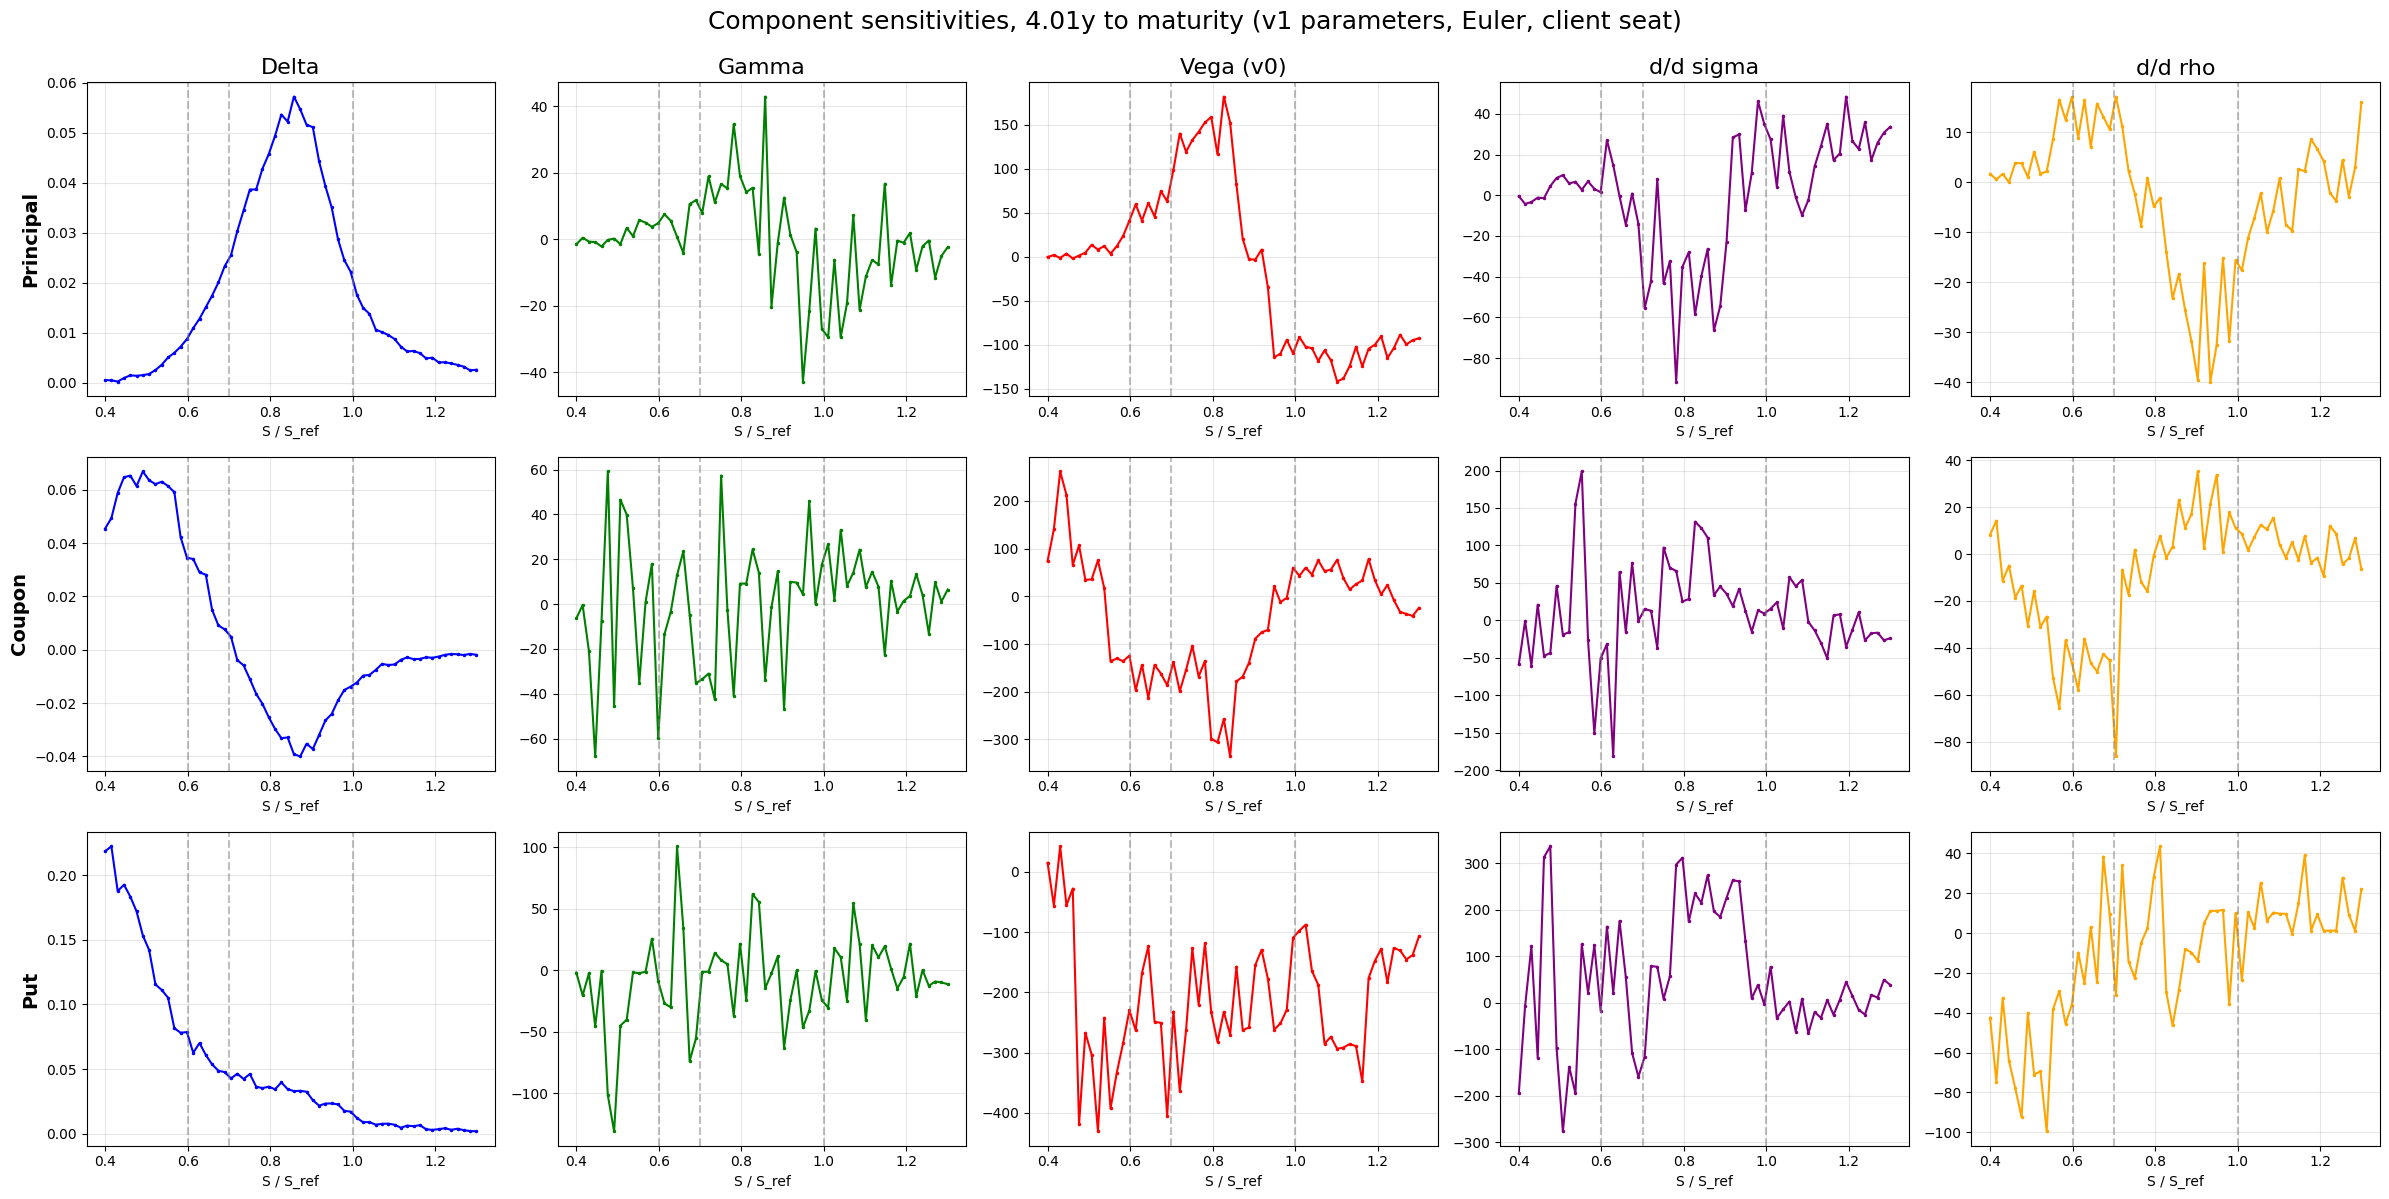

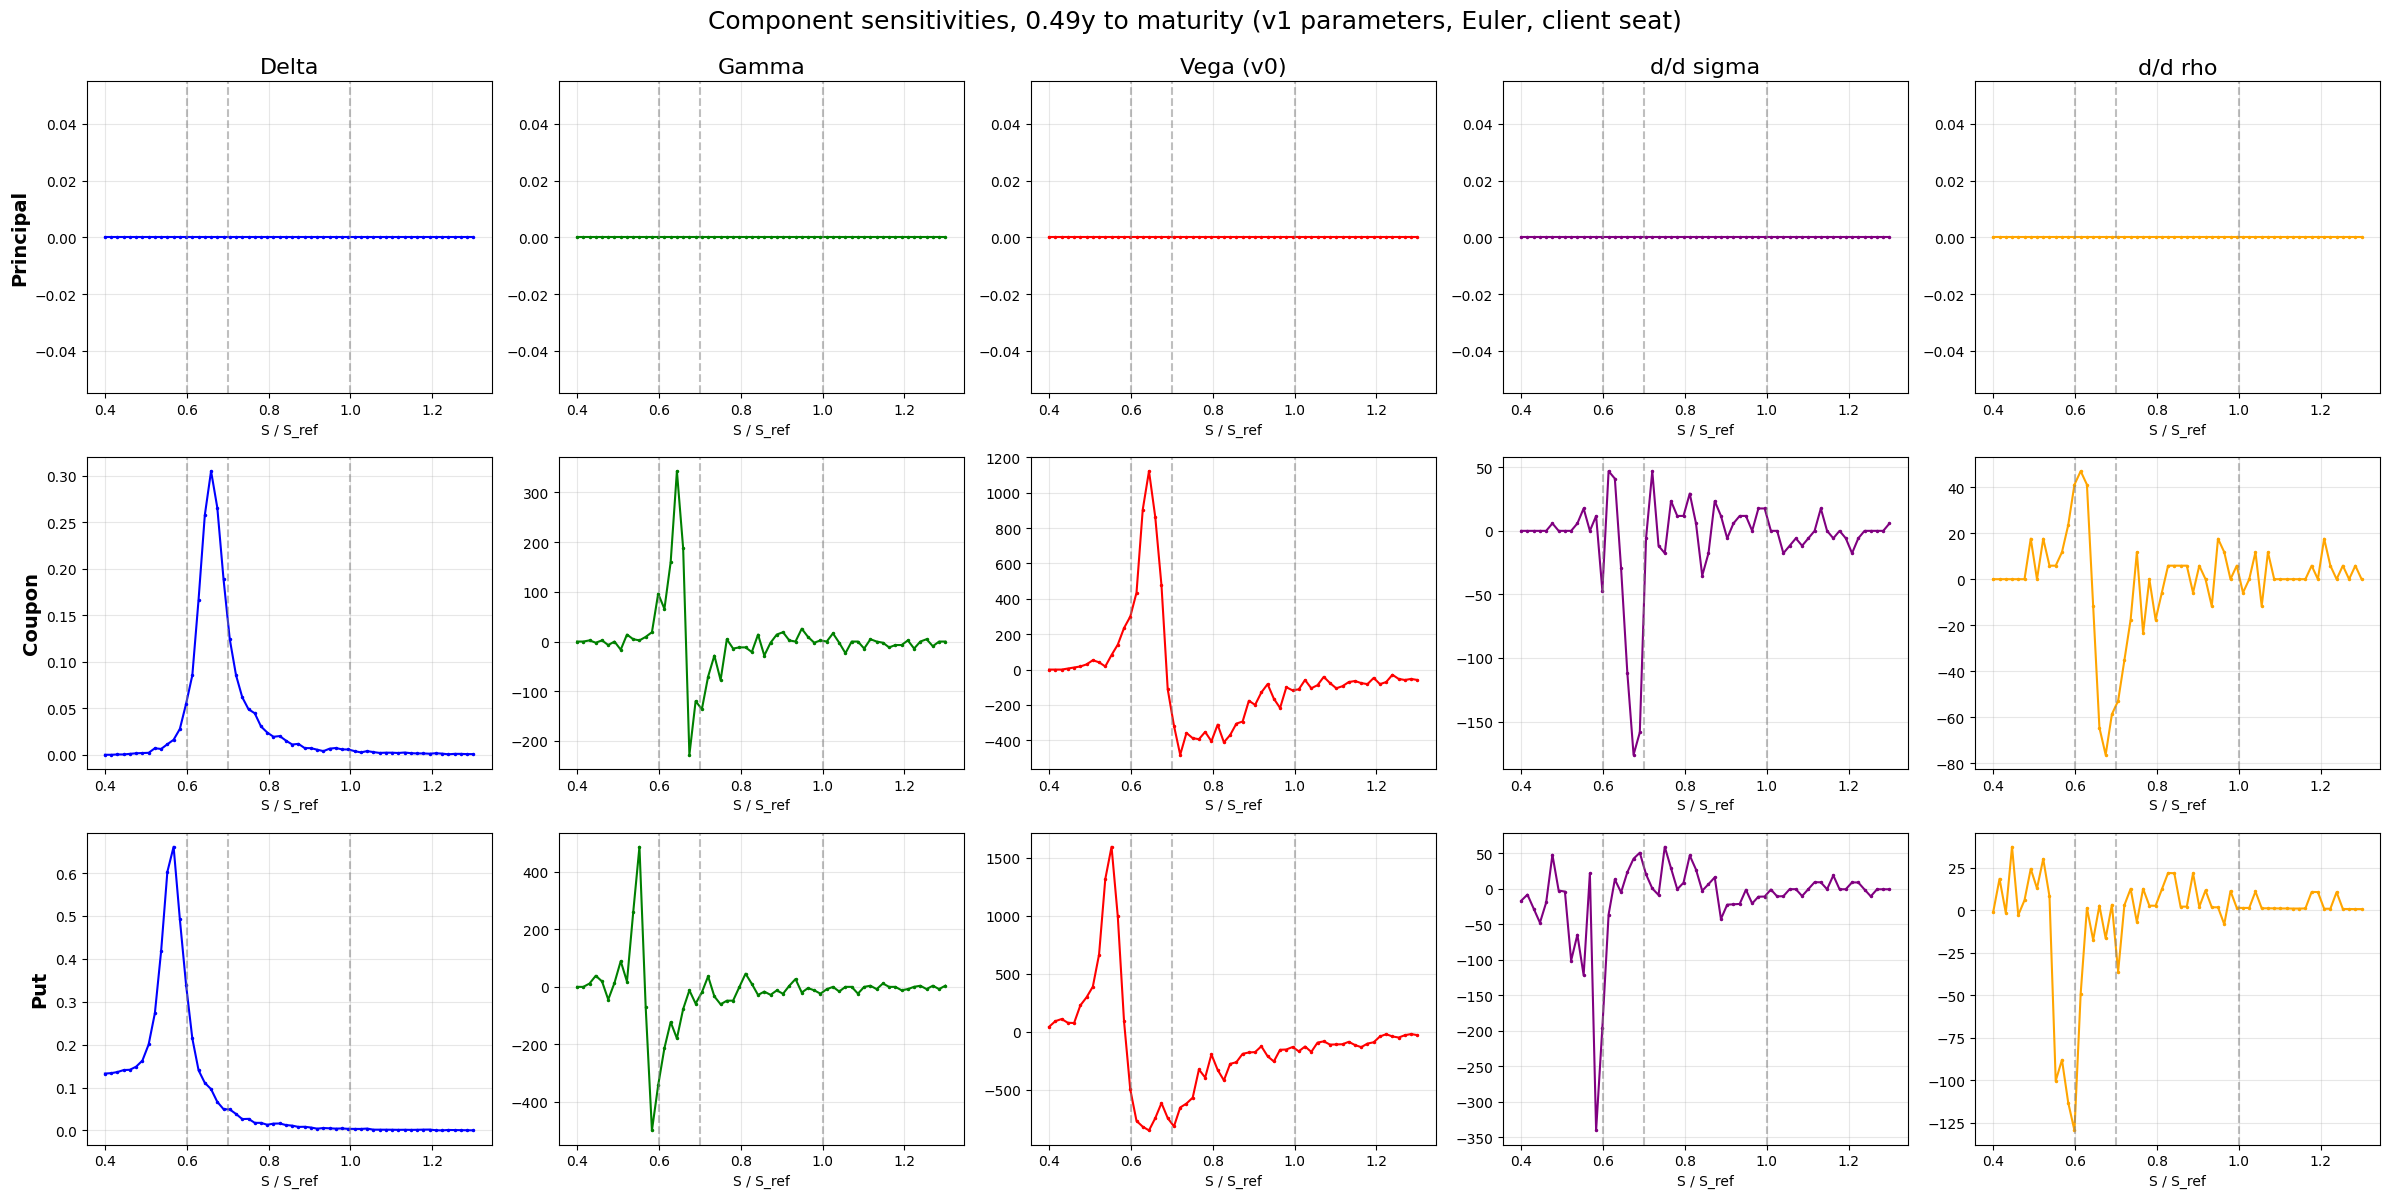

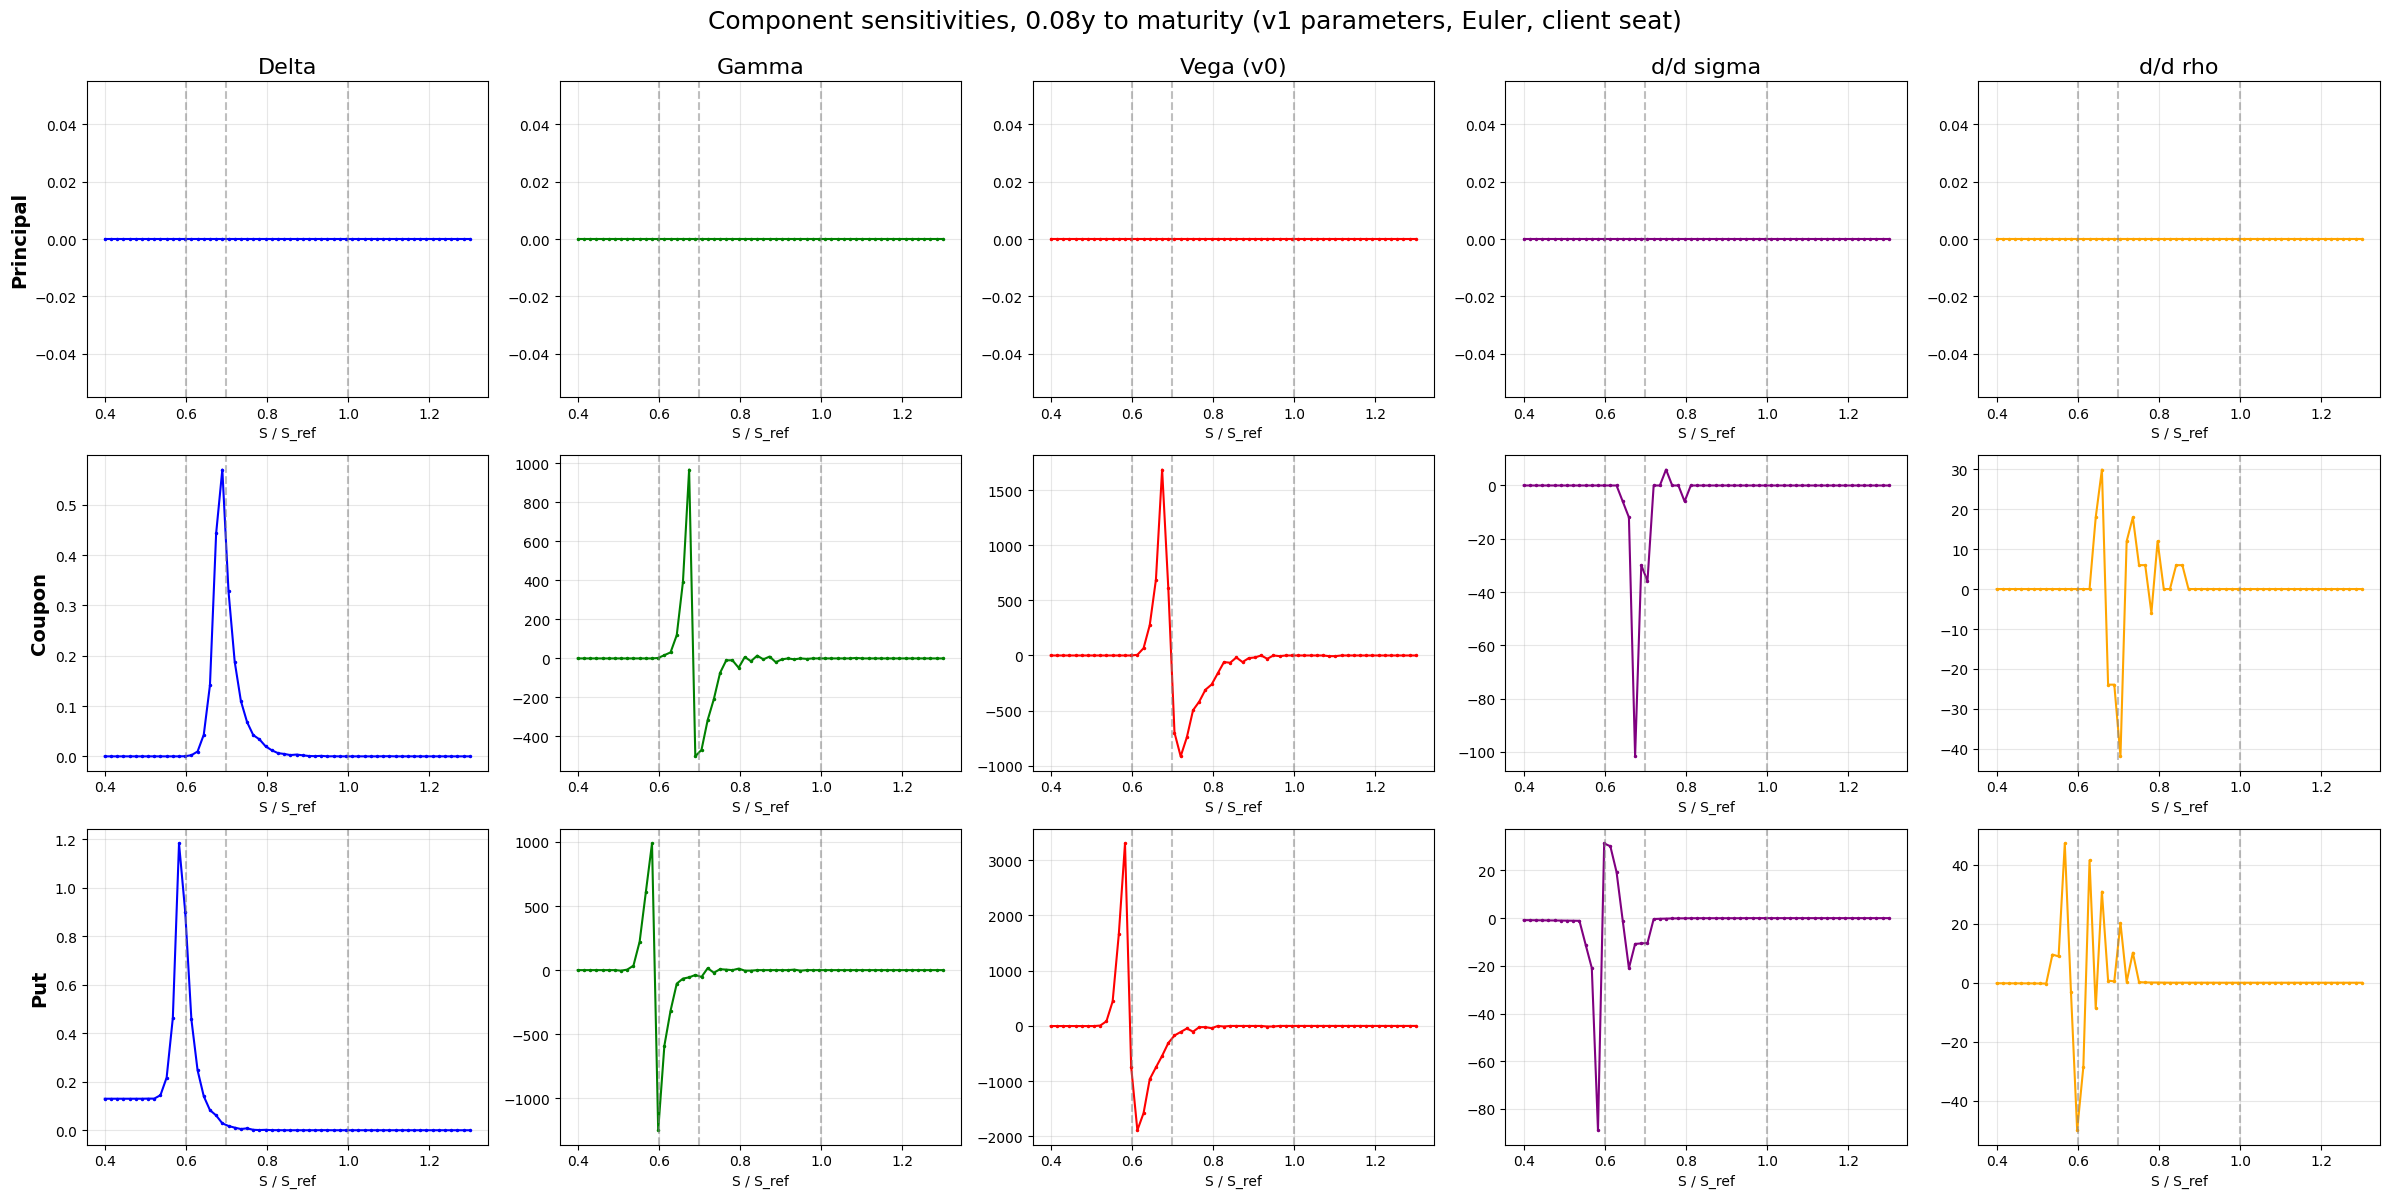

In [7]:
def plot_component_greeks(base_pricer, product_params, time_to_maturity=None):
    s_ref = base_pricer.S_ref; spots = np.linspace(s_ref * 0.4, s_ref * 1.3, 60)
    maturity_date = datetime.strptime(product_params['full_schedule'][-1], "%Y-%m-%d")
    if time_to_maturity is not None:
        T_sim = time_to_maturity; sim_date = maturity_date - timedelta(days=int(T_sim * 365))
    else:
        T_sim = max((maturity_date - PRICING_DATE).days / 365, 0.01); sim_date = PRICING_DATE
    obs_sim = HestonAutocallPricer.schedule_to_times(product_params['full_schedule'], sim_date)
    with suppress_stdout(): gp = base_pricer.generate_greek_paths(T_max=T_sim, n_paths=10000, obs_times=obs_sim)
    history = {'Principal': [], 'Coupon': [], 'Put': []}
    for s in spots:
        temp = HestonAutocallPricer(s, s_ref, base_pricer.r_curve_func, base_pricer.q_curve_func, PARAMS_V1, scheme='euler')
        with suppress_stdout(): gg = temp.compute_sensitivities(product_params, path_set=gp, pricing_date=sim_date)
        for c in history: history[c].append(gg[c])
    del gp
    fig, axes = plt.subplots(3, 5, figsize=(24, 12)); greeks = ['Delta', 'Gamma', 'Vega', 'Volga', 'Rho']; colors = ['blue', 'green', 'red', 'purple', 'orange']
    for i, comp in enumerate(history):
        for j, gk in enumerate(greeks):
            ax = axes[i, j]; ax.plot(spots / s_ref, [d[gk] for d in history[comp]], '.-', color=colors[j], lw=1.5, markersize=3); ax.grid(alpha=0.3)
            if i == 0: ax.set_title({'Vega': 'Vega (v0)', 'Volga': 'd/d sigma', 'Rho': 'd/d rho'}.get(gk, gk), fontsize=16)
            if j == 0: ax.set_ylabel(comp, fontsize=14, fontweight='bold')
            for lvl in [0.6, 0.7, 1.0]: ax.axvline(lvl, color='gray', ls='--', alpha=0.5)
            ax.set_xlabel('S / S_ref')
    plt.suptitle(f"Component sensitivities, {T_sim:.2f}y to maturity (v1 parameters, Euler, client seat)", fontsize=18, y=0.995); plt.tight_layout(); plt.show()
pr_scan = HestonAutocallPricer(S0, S0, rate_curve_func, q_eff, PARAMS_V1, scheme='euler'); PP = {**PRODUCT_V1, 'payment_lag_days': 0}
plot_component_greeks(pr_scan, PP); plot_component_greeks(pr_scan, PP, time_to_maturity=180/365); plot_component_greeks(pr_scan, PP, time_to_maturity=30/365)


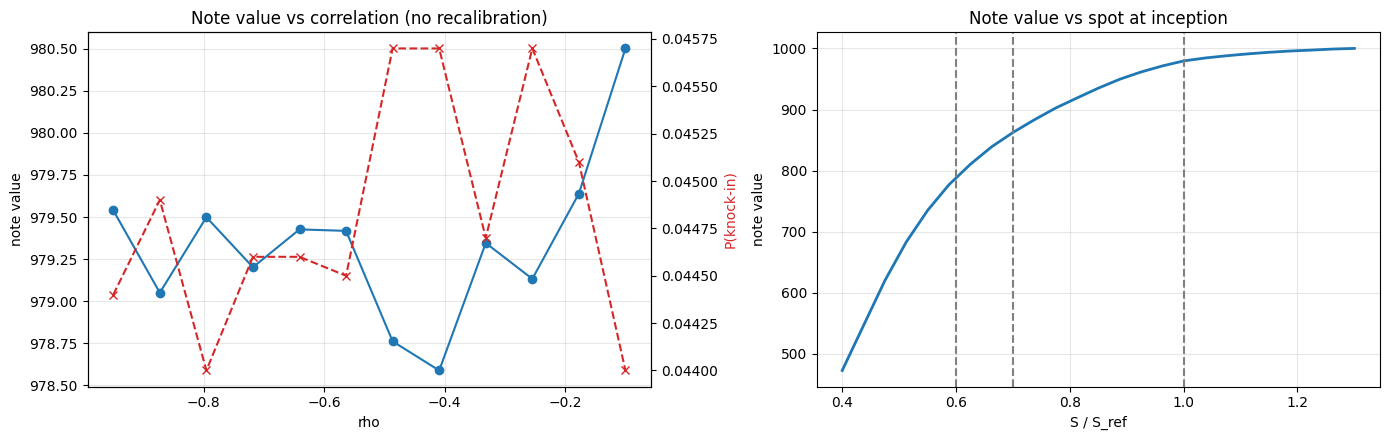

rho scan: value 978.6 to 980.5, P(KI) 0.044 to 0.046 across rho -0.95..-0.10 (10k paths, noise about 1.5 per 1,000)


In [8]:
# correlation scan (rho from -0.95 to -0.1, other parameters fixed, 10,000 paths, same seed) and the price profile against spot
rho_grid = np.linspace(-0.95, -0.1, 12); prices_rho = []; ki_rho = []
for rho in rho_grid:
    p_ = HestonAutocallPricer(S0, S0, rate_curve_func, q_eff, [PARAMS_V1[0], PARAMS_V1[1], PARAMS_V1[2], rho, PARAMS_V1[4]], scheme='euler')
    p_.run_simulation(T_MAX, 252, 10000, obs_times=OBS, seed=42, verbose=False); prices_rho.append(p_.price_structure(**PP, pricing_date=PRICING_DATE, verbose=False)[0]); ki_rho.append(p_.outcomes['prob_knock_in'])
spot_grid = np.linspace(0.4, 1.3, 25) * S0; prices_spot = []
for s in spot_grid:
    p_ = HestonAutocallPricer(s, S0, rate_curve_func, q_eff, PARAMS_V1, scheme='euler'); p_.run_simulation(T_MAX, 252, 10000, obs_times=OBS, seed=42, verbose=False)
    prices_spot.append(p_.price_structure(**PP, pricing_date=PRICING_DATE, verbose=False)[0])
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].plot(rho_grid, prices_rho, 'o-'); ax[0].set_xlabel('rho'); ax[0].set_ylabel('note value'); ax[0].set_title('Note value vs correlation (no recalibration)'); ax[0].grid(alpha=0.3)
a2 = ax[0].twinx(); a2.plot(rho_grid, ki_rho, 'x--', color='tab:red'); a2.set_ylabel('P(knock-in)', color='tab:red')
ax[1].plot(spot_grid / S0, prices_spot, lw=2); [ax[1].axvline(l, color='gray', ls='--') for l in [0.6, 0.7, 1.0]]; ax[1].set_xlabel('S / S_ref'); ax[1].set_ylabel('note value'); ax[1].set_title('Note value vs spot at inception'); ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()
print(f"rho scan: value {min(prices_rho):.1f} to {max(prices_rho):.1f}, P(KI) {min(ki_rho):.3f} to {max(ki_rho):.3f} across rho {rho_grid[0]:.2f}..{rho_grid[-1]:.2f} (10k paths, noise about 1.5 per 1,000)")


## 7. Price attribution across conventions, and rates

In [9]:
def price_with(params, scheme, drift, lag):
    qf = q_eff if drift == 'flat' else q_func
    p_ = HestonAutocallPricer(S0, S0, rate_curve_func, qf, params, scheme=scheme); p_.run_simulation(T_MAX, 252, 50000, obs_times=OBS, seed=42, verbose=False)
    return p_.price_structure(**{**PRODUCT_V1, 'payment_lag_days': lag}, pricing_date=PRICING_DATE, verbose=False)[0], p_.std_error, p_
cal6u = FFTCalibrator(df_v1[df_v1['T'] >= SHORT_T], S0, rate_curve_func, model=HestonModel(), objective='iv'); PARAMS_V2U = cal6u.calibrate(verbose=False, seed=42).x
df_f = df_v1[df_v1['clean']].reset_index(drop=True); cal6f = FFTCalibrator(df_f[df_f['T'] >= SHORT_T], S0, rate_curve_func, model=HestonModel(), objective='iv'); PARAMS_V2 = cal6f.calibrate(verbose=False, seed=42).x
steps = [('v1: Euler, flat drift, no lag (v1 engine above)', None, None, None, price), ('v2 engine, Euler, flat drift, no lag', PARAMS_V1, 'euler', 'flat', 0), ('+ QE scheme', PARAMS_V1, 'qe', 'flat', 0),
         ('+ term-structure drift from the curves', PARAMS_V1, 'qe', 'curve', 0), ('+ 7-day payment lag', PARAMS_V1, 'qe', 'curve', 7),
         ('+ vol objective, 6M+ fit, unfiltered quotes', PARAMS_V2U, 'qe', 'curve', 7), ('+ quote filter: the main.ipynb pipeline', PARAMS_V2, 'qe', 'curve', 7)]
rows = []; prev = None
for label, prm, sch, dr, lag in steps:
    if prm is None: px_ = lag; se_ = MC_SE
    else: px_, se_, p_ = price_with(prm, sch, dr, lag)
    rows.append({'step': label, 'price': px_, 'change': (px_ - prev) if prev is not None else np.nan, 's.e.': se_}); prev = px_
ATTRIB = pd.DataFrame(rows).set_index('step'); display(ATTRIB.round(3))
print(f"vol-objective 6M+ parameters: unfiltered {np.round(PARAMS_V2U, 4)}; filtered (main.ipynb) {np.round(PARAMS_V2, 4)}")
# rates: discounting only (forward fixed) and full shift; theta over one week
px0, _, p0 = price_with(PARAMS_V1, 'euler', 'flat', 0)
r0 = p0.r_curve_func; p0.r_curve_func = lambda t: r0(t) + 0.0001; px_bp = p0.price_structure(**PP, pricing_date=PRICING_DATE, verbose=False)[0]; p0.r_curve_func = r0
p_full = HestonAutocallPricer(S0, S0, lambda t: rate_curve_func(t) + 0.001, lambda t: rate_curve_func(t) + 0.001 - MU_FLAT - 0.001, PARAMS_V1, scheme='euler')   # forward moves with the rate
p_full.run_simulation(T_MAX, 252, 50000, obs_times=OBS, seed=42, verbose=False); px_full = p_full.price_structure(**PP, pricing_date=PRICING_DATE, verbose=False)[0]
RATES = {'DV01 discounting only': px_bp - px0, 'full +10bp shift': px_full - px0}
print(f"Rates: discounting only (forward fixed) {RATES['DV01 discounting only']:+.3f} per bp; full +10 bp shift (forward moves too) {RATES['full +10bp shift']:+.2f}")
PD7 = PRICING_DATE + timedelta(days=7); OBS7 = HestonAutocallPricer.schedule_to_times(SCHEDULE, PD7)
p7 = HestonAutocallPricer(S0, S0, rate_curve_func, q_eff, PARAMS_V1, scheme='euler'); p7.run_simulation(OBS7[-1], 252, 50000, obs_times=OBS7, seed=42, verbose=False)
THETA = p7.price_structure(**PP, pricing_date=PD7, verbose=False)[0] - px0; print(f"one week of theta (same spot and parameters): {THETA:+.2f} (s.e. about 1)")


,price,change,s.e.
step,,,
"v1: Euler, flat drift, no lag (v1 engine above)",975.837,NaN,0.708
"v2 engine, Euler, flat drift, no lag",975.845,0.007,0.708
+ QE scheme,976.318,0.473,0.702
+ term-structure drift from the curves,976.003,-0.314,0.705
+ 7-day payment lag,975.077,-0.926,0.704
"+ vol objective, 6M+ fit, unfiltered quotes",973.837,-1.240,0.737
+ quote filter: the main.ipynb pipeline,975.426,1.589,0.697


vol-objective 6M+ parameters: unfiltered [ 0.8471  0.0668  0.8997 -0.5935  0.0315]; filtered (main.ipynb) [ 2.8733  0.0527  1.5257 -0.6096  0.0247]


Rates: discounting only (forward fixed) -0.142 per bp; full +10 bp shift (forward moves too) -0.90


one week of theta (same spot and parameters): +1.49 (s.e. about 1)


## 8. Calibration objectives on the v1 quotes

In [10]:
names = {'price': 'price RMSE  [v1]', 'relprice': 'relative price RMSE', 'vega': 'vega-weighted price', 'iv_uniform': 'vol RMSE, uniform', 'iv_spread': 'vol RMSE, 1/spread^2  [v2]', 'iv_huber': 'Huber vol loss'}
rows = []; OBJ_PARAMS = {}
for mode, label in names.items():
    c = ObjectiveCalibrator(df_v1, S0, rate_curve_func, mode=mode); t0 = time.perf_counter(); r_ = c.calibrate(verbose=False, seed=42); OBJ_PARAMS[mode] = r_.x
    rows.append({**score(r_.x, label=label), 'seconds': time.perf_counter() - t0, 'sigma': r_.x[2], 'rho': r_.x[3], 'Feller ratio': 2 * r_.x[0] * r_.x[1] / r_.x[2]**2})
OBJECTIVES = pd.DataFrame(rows).set_index('label'); display(OBJECTIVES.round(3))


,vol RMSE all,vol RMSE 1M-3M,vol RMSE 6M+,max |vol err|,price RMSE,price RMSE 6M+,price RMSE % of spot,rel. price RMSE OTM %,median |rel| %,product strikes,product strikes (clean quotes),seconds,sigma,rho,Feller ratio
label,,,,,,,,,,,,,,,
price RMSE [v1],1.663,2.238,0.988,19.044,20.810,27.396,0.270,23.981,4.751,0.421,0.231,19.316,1.021,-0.623,0.177
relative price RMSE,2.356,1.990,2.612,14.209,35.453,47.391,0.461,25.965,5.978,3.308,3.116,18.653,1.628,-0.658,0.232
vega-weighted price,1.099,1.358,0.837,12.982,22.488,29.307,0.292,23.526,5.882,0.383,0.194,17.798,1.605,-0.620,0.124
"vol RMSE, uniform",1.064,1.223,0.918,9.883,23.141,29.627,0.301,46.711,9.020,0.429,0.240,33.010,2.445,-0.564,0.078
"vol RMSE, 1/spread^2 [v2]",1.064,1.238,0.901,10.467,22.955,29.609,0.298,37.896,8.196,0.473,0.308,34.212,1.875,-0.581,0.093
Huber vol loss,1.100,1.362,0.833,13.038,22.482,29.529,0.292,31.323,5.168,0.341,0.151,34.405,1.631,-0.583,0.122


## 9. Optimisers on the v1 objective (price RMSE, 5 Heston parameters)

In [11]:
class PriceCal(ObjectiveCalibrator):
    def residual_vector(self, params):
        try:
            pv_ = self.price_surface(params)
            if not np.all(np.isfinite(pv_)): raise ValueError
            return (pv_ - self.flat_market) / np.sqrt(len(self.flat_market))
        except Exception:
            return np.full(len(self.flat_market), 100.0)
cal_opt = PriceCal(df_v1, S0, rate_curve_func, mode='price')
opt_methods = [('de_lbfgs', 'DE best1bin + L-BFGS-B  [v1]', [42, 7]), ('de', 'DE, no local step', [42, 7]), ('de_rand1', 'DE rand1bin', [42, 7]), ('de_c2b', 'DE currenttobest1bin', [42, 7]), ('de_small_pop', 'DE small population', [42, 7]),
               ('dual_annealing', 'dual annealing', [42, 7]), ('basinhopping', 'basin hopping', [42, 7]), ('shgo', 'SHGO', [42]), ('nelder_mead', 'Nelder-Mead from heuristic start', [42]),
               ('lbfgs_multistart', 'L-BFGS-B, 12 LHS starts', [42, 7]), ('least_squares', 'least_squares (trf) from heuristic start', [42]), ('least_squares_multistart', 'least_squares, 6 starts', [42, 7])]
rows = []
for m, label, seeds in opt_methods:
    runs = [run_optimizer(cal_opt, m, seed=s) for s in seeds]; funs = [r_['fun'] for r_ in runs]; best = min(runs, key=lambda r_: r_['fun'])
    rows.append({'optimiser': label, 'best price RMSE': min(funs), 'worst price RMSE': max(funs), 'evaluations': np.mean([r_['nfev'] for r_ in runs]), 'seconds': np.mean([r_['seconds'] for r_ in runs]), 'kappa': best['x'][0], 'sigma': best['x'][2], 'rho': best['x'][3]})
    print(f"{label:45s} best {min(funs):.4f} worst {max(funs):.4f} {np.mean([r_['seconds'] for r_ in runs]):6.1f} s")
OPTIMISERS = pd.DataFrame(rows).set_index('optimiser'); display(OPTIMISERS.round(4))


DE best1bin + L-BFGS-B  [v1]                  best 20.8104 worst 20.8104   18.7 s


DE, no local step                             best 20.8215 worst 20.8764   17.3 s


DE rand1bin                                   best 22.5498 worst 23.6183   17.3 s


DE currenttobest1bin                          best 20.9701 worst 21.4182   17.3 s


DE small population                           best 20.8108 worst 20.8110    9.4 s


...

Nelder-Mead from heuristic start              best 20.8104 worst 20.8104    2.4 s


L-BFGS-B, 12 LHS starts                       best 20.8104 worst 20.8104   46.7 s


least_squares (trf) from heuristic start      best 20.8104 worst 20.8104    0.3 s


least_squares, 6 starts                       best 20.8104 worst 20.8104    3.7 s


,best price RMSE,worst price RMSE,evaluations,seconds,kappa,sigma,rho
optimiser,,,,,,,
DE best1bin + L-BFGS-B [v1],20.8104,20.8104,4083.0,18.7377,1.7026,1.0213,-0.6230
"DE, no local step",20.8215,20.8764,3825.0,17.2599,1.6373,1.0052,-0.6157
DE rand1bin,22.5498,23.6183,3825.0,17.3020,5.9822,2.7728,-0.6307
DE currenttobest1bin,20.9701,21.4182,3825.0,17.3269,2.1879,1.2967,-0.5852
DE small population,20.8108,20.8110,2112.5,9.3972,1.6892,1.0200,-0.6210
dual annealing,21.3711,23.0149,898.0,4.8110,2.6665,1.5153,-0.5393
basin hopping,20.8104,20.8104,4560.0,32.5524,1.7026,1.0213,-0.6230
SHGO,20.8104,20.8104,1257.0,9.1496,1.7027,1.0213,-0.6230
Nelder-Mead from heuristic start,20.8104,20.8104,526.0,2.4473,1.7026,1.0213,-0.6230


## 10. Models: Heston, Bates, double Heston, rough Heston on the v1 quotes (vol objective, all 8 expiries), with the note priced under each on v1 conventions

Heston (vol objective)          34 s  kappa=2.9285, theta=0.0558, sigma=1.8750, rho=-0.5807, v0=0.0217


Bates                           78 s  kappa=2.7481, theta=0.0544, sigma=2.5928, rho=-0.7546, v0=0.0115, lam=5.0000, muJ=-0.0427, sigJ=0.0050


Double Heston                  239 s  kappa1=1.7668, theta1=0.0658, sigma1=3.3980, rho1=-0.9586, v01=0.0048, kappa2=6.7788, theta2=0.0188, sigma2=0.8052, rho2=-0.5017, v02=0.0153


Rough Heston                   839 s  kappa=0.0222, theta=1.0000, sigma=0.4957, rho=-0.5884, v0=0.0251, H=0.0561


,vol RMSE all,vol RMSE 1M-3M,vol RMSE 6M+,max |vol err|,price RMSE,price RMSE 6M+,price RMSE % of spot,rel. price RMSE OTM %,median |rel| %,product strikes,product strikes (clean quotes),params,seconds
label,,,,,,,,,,,,,
v1 Heston (price objective),1.663,2.238,0.988,19.045,20.810,27.396,0.270,23.979,4.747,0.421,0.232,5,20.908
Heston (vol objective),1.064,1.238,0.901,10.467,22.955,29.609,0.298,37.896,8.196,0.473,0.308,5,33.912
Bates,0.605,0.491,0.682,9.472,20.486,27.343,0.266,9.710,4.293,0.590,0.486,8,77.866
Double Heston,0.510,0.258,0.643,9.359,19.872,26.613,0.258,7.570,1.943,0.559,0.464,10,239.443
Rough Heston,0.947,1.034,0.872,9.184,21.768,28.833,0.283,27.594,5.872,0.471,0.449,6,838.954


,v1 Heston (price objective),Heston (vol objective),Bates,Double Heston,Rough Heston
0.09y,4.172,2.192,1.237,0.610,1.584
0.25y,1.972,1.112,0.353,0.197,0.969
0.50y,1.056,0.893,0.426,0.320,0.791
1.00y,0.546,0.770,0.623,0.500,0.843
1.31y,0.514,0.581,0.566,0.495,0.815
2.21y,0.413,0.341,0.527,0.576,0.497
3.22y,1.024,0.898,0.856,0.872,0.901
4.22y,1.899,1.864,1.814,1.829,1.791
ALL,1.663,1.064,0.605,0.510,0.947


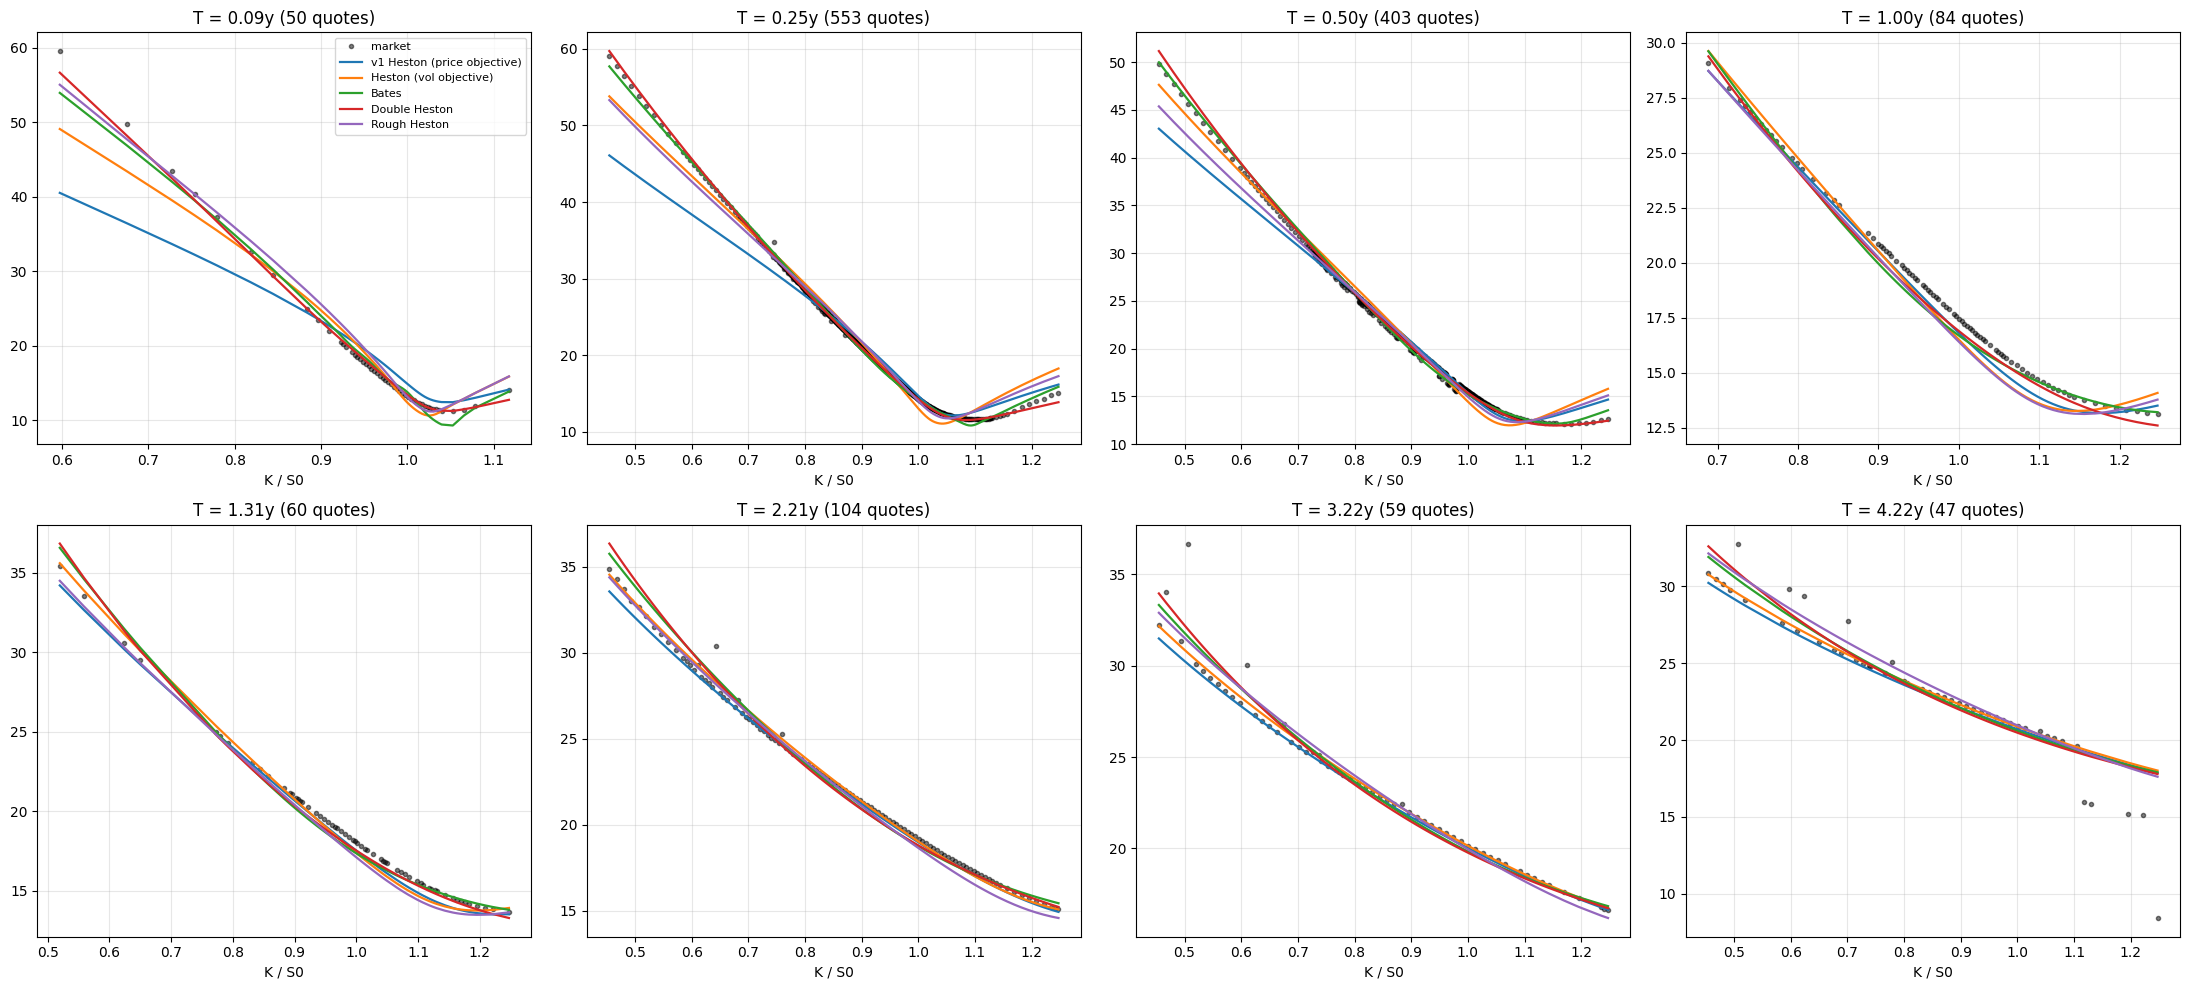

,price,s.e.,put leg,P(call 1Y),P(KI),E[level|KI]
model,,,,,,
v1 Heston (price objective),976.3177,0.7025,-25.1555,0.7087,0.0488,0.3705
Heston (vol objective),978.5006,0.6866,-23.8782,0.7212,0.0459,0.3641
Bates,980.1932,0.6826,-23.0156,0.6798,0.0427,0.3414
Double Heston,979.4145,0.6994,-23.7182,0.6859,0.0428,0.3239


                               price   s.e.  put leg  P(call 1Y)  P(KI)  E[level|KI]
model                                                                               
v1 Heston (price objective)  976.318  0.702  -25.156       0.709  0.049        0.370
Heston (vol objective)       978.501  0.687  -23.878       0.721  0.046        0.364
Bates                        980.193  0.683  -23.016       0.680  0.043        0.341
Double Heston                979.414  0.699  -23.718       0.686  0.043        0.324


In [12]:
MODELS = [('Heston (vol objective)', HestonModel(), 50, [42]), ('Bates', BatesModel(), 60, [42]), ('Double Heston', DoubleHestonModel(), 60, [42, 7]), ('Rough Heston', RoughHestonModel(), 60, [42, 7])]
fits = {'v1 Heston (price objective)': {'model': HestonModel(), 'params': PARAMS_V1, 'cal': cal_iv, 'seconds': V1_SECS}}
for name, model, maxiter, seeds in MODELS:
    c = FFTCalibrator(df_v1, S0, rate_curve_func, model=model, objective='iv'); t0 = time.perf_counter(); best = None
    for sd in seeds:
        r_ = c.calibrate(verbose=False, maxiter=maxiter, seed=sd)
        if best is None or r_.fun < best.fun: best = r_
    fits[name] = {'model': model, 'params': best.x, 'cal': c, 'seconds': time.perf_counter() - t0}
    print(f"{name:28s} {fits[name]['seconds']:5.0f} s  " + ", ".join(f"{k}={v:.4f}" for k, v in zip(model.param_names, best.x)))
rows = [{**score(f['params'], f['cal'], name), 'params': len(f['params']), 'seconds': f['seconds']} for name, f in fits.items()]
MODELS_TABLE = pd.DataFrame(rows).set_index('label'); display(MODELS_TABLE.round(3))
per_exp = pd.DataFrame({name: f['cal'].fit_report(f['params']).set_index('T')['IV RMSE (vol pts)'] for name, f in fits.items()}); per_exp.index = [f"{t:.2f}y" if t != 'ALL' else 'ALL' for t in per_exp.index]; display(per_exp.round(3))
# smiles
cal0 = cal_iv; nT = len(cal0.data_batches); fig, axes = plt.subplots(2, 4, figsize=(22, 10)); axes = axes.flatten()
for i, b in enumerate(cal0.data_batches):
    ax = axes[i]; m = cal0.flat_T == b['T']; rT = cal0.r_curve(b['T']); mon = b['strikes'] / S0
    ax.plot(mon, 100 * cal0.market_iv[m], 'ko', ms=3, alpha=0.5, label='market')
    for name, f in fits.items():
        iv = implied_vol_call_vec(f['cal'].price_calls(f['params'], b['T'], b['strikes'], b['q']), S0, b['strikes'], b['T'], rT, b['q']); ax.plot(mon, 100 * iv, lw=1.6, label=name)
    ax.set_title(f"T = {b['T']:.2f}y ({m.sum()} quotes)"); ax.grid(alpha=0.3); ax.set_xlabel('K / S0')
    if i == 0: ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
# note under each model, v1 conventions (flat drift, no lag)
rows = []
for name, mname in [('v1 Heston (price objective)', 'heston'), ('Heston (vol objective)', 'heston'), ('Bates', 'bates'), ('Double Heston', 'double_heston')]:
    p_ = MultiModelPricer(S0, S0, rate_curve_func, q_eff, fits[name]['params'], model=mname); p_.run_simulation(T_MAX, 252, 50000, obs_times=OBS, seed=42, verbose=False)
    px_ = p_.price_structure(**PP, pricing_date=PRICING_DATE, verbose=False); oc = p_.outcomes
    rows.append({'model': name, 'price': px_[0], 's.e.': p_.std_error, 'put leg': px_[3], 'P(call 1Y)': oc['call_prob_by_date'][0], 'P(KI)': oc['prob_knock_in'], 'E[level|KI]': oc['mean_perf_given_ki']})
MODEL_PRICES = pd.DataFrame(rows).set_index('model'); display(MODEL_PRICES.round(4)); print(MODEL_PRICES.round(3).to_string())


## 11. The Feller condition: is the violation a defect?

In [13]:
def unpack_feller(y):   # y = (kappa, theta, s, rho, v0) with sigma = s * sqrt(2 kappa theta), s <= 1 enforces Feller exactly
    return np.array([y[0], y[1], y[2] * np.sqrt(2 * y[0] * y[1]), y[3], y[4]])
fb = [cal_v1.bounds[0], cal_v1.bounds[1], (0.05, 1.0), cal_v1.bounds[3], cal_v1.bounds[4]]
rf = optimize.differential_evolution(lambda y: cal_v1.objective_function(unpack_feller(y)), fb, seed=42, maxiter=60, popsize=15, tol=1e-6, polish=True); PARAMS_FELLER = unpack_feller(rf.x)
rows = [{**score(PARAMS_V1, label='v1, unconstrained'), 'sigma': PARAMS_V1[2], 'rho': PARAMS_V1[3], 'Feller ratio': 2*PARAMS_V1[0]*PARAMS_V1[1]/PARAMS_V1[2]**2},
        {**score(PARAMS_FELLER, label='v1 objective, Feller enforced'), 'sigma': PARAMS_FELLER[2], 'rho': PARAMS_FELLER[3], 'Feller ratio': 2*PARAMS_FELLER[0]*PARAMS_FELLER[1]/PARAMS_FELLER[2]**2}]
FELLER = pd.DataFrame(rows).set_index('label'); display(FELLER.round(3))
pf = v1.HestonAutocallPricer(S0, S0, rate_curve_func, q_func, PARAMS_FELLER); np.random.seed(42); quiet(pf.run_simulation, T_max=T_MAX, steps_per_year=252, n_paths=50000)
FELLER_PRICE = quiet(pf.price_structure, **PRODUCT_V1, pricing_date=PRICING_DATE)[0]
print(f"Feller-constrained parameters {np.round(PARAMS_FELLER, 4)}: note {FELLER_PRICE:.2f} (v1 {price:.2f}); PDE {price_autocall_pde(PARAMS_FELLER, S0, rate_curve_func, q_eff, OBS, payment_lag_days=0)[0]:.2f}")
# engine check and the kappa-sigma ridge at the v1 optimum
class COSCal(FFTCalibrator):
    def price_calls(self, params, T, strikes, q_t): return price_cos(self.model, params, self.S0, strikes, T, float(self.r_curve(T)), q_t, N=256)
cc = COSCal(df_v1, S0, rate_curve_func, model=HestonModel(), objective='price'); r_cos = optimize.minimize(cc.objective_function, PARAMS_V1, method='L-BFGS-B', bounds=cc.bounds, tol=1e-10)
print(f"same objective with the COS engine, polished from the v1 optimum: sigma {r_cos.x[2]:.4f} (FFT: {PARAMS_V1[2]:.4f}), RMSE {r_cos.fun:.4f}")
print("kappa-sigma ridge (sigma^2/kappa fixed, theta/rho/v0 re-optimised):")
for kap in [1.0, 1.5, PARAMS_V1[0], 3.0, 4.5]:
    sig = PARAMS_V1[2] * np.sqrt(kap / PARAMS_V1[0]); rr = optimize.minimize(lambda y: cal_v1.objective_function(np.array([kap, y[0], sig, y[1], y[2]])), PARAMS_V1[[1, 3, 4]], method='Nelder-Mead', options={'xatol': 1e-6, 'fatol': 1e-9, 'maxfev': 600})
    print(f"  kappa {kap:.2f} sigma {sig:.2f}: price RMSE {rr.fun:.4f}")


,vol RMSE all,vol RMSE 1M-3M,vol RMSE 6M+,max |vol err|,price RMSE,price RMSE 6M+,price RMSE % of spot,rel. price RMSE OTM %,median |rel| %,product strikes,product strikes (clean quotes),sigma,rho,Feller ratio
label,,,,,,,,,,,,,,
"v1, unconstrained",1.663,2.238,0.988,19.045,20.81,27.396,0.27,23.979,4.747,0.421,0.232,1.021,-0.623,0.177
"v1 objective, Feller enforced",5.014,6.634,3.180,59.577,26.14,33.277,0.34,43.354,14.995,1.537,1.346,0.327,-0.999,1.000


Feller-constrained parameters [ 1.0792  0.0495  0.3269 -0.999   0.0207]: note 974.22 (v1 975.84); PDE 974.42
same objective with the COS engine, polished from the v1 optimum: sigma 1.0212 (FFT: 1.0212), RMSE 20.8106
kappa-sigma ridge (sigma^2/kappa fixed, theta/rho/v0 re-optimised):


  kappa 1.00 sigma 0.78: price RMSE 21.1680


  kappa 1.50 sigma 0.96: price RMSE 20.8320


  kappa 1.70 sigma 1.02: price RMSE 20.8104


  kappa 3.00 sigma 1.36: price RMSE 21.2689


  kappa 4.50 sigma 1.66: price RMSE 22.1677


## 12. Vanilla pricing engines and vol inversion

In [14]:
model = HestonModel(); P = PARAMS_V1
engines = {'Lewis FFT + spline [v1]': lambda b, K: cal_iv.price_calls(P, b['T'], K, b['q']), 'Lewis Gauss-Legendre 1500': lambda b, K: price_lewis_gauss_legendre(model, P, S0, K, b['T'], cal_iv.r_curve(b['T']), b['q']),
           'COS N=256': lambda b, K: price_cos(model, P, S0, K, b['T'], cal_iv.r_curve(b['T']), b['q'], N=256), 'Carr-Madan FFT alpha=1.5': lambda b, K: price_carr_madan_fft(model, P, S0, K, b['T'], cal_iv.r_curve(b['T']), b['q'], alpha=1.5),
           'Carr-Madan FFT alpha=0.75': lambda b, K: price_carr_madan_fft(model, P, S0, K, b['T'], cal_iv.r_curve(b['T']), b['q'], alpha=0.75), 'Heston 1993 two integrals': lambda b, K: price_heston_two_integral(model, P, S0, K, b['T'], cal_iv.r_curve(b['T']), b['q'])}
refs = {b['T']: price_lewis_reference(model, P, S0, b['strikes'], b['T'], cal_iv.r_curve(b['T']), b['q']) for b in cal_iv.data_batches}
rows = []
for name, fn in engines.items():
    t0 = time.perf_counter(); out = [fn(b, b['strikes']) for b in cal_iv.data_batches]; secs = time.perf_counter() - t0
    e = np.concatenate([np.abs(p - refs[b['T']]) for b, p in zip(cal_iv.data_batches, out)])
    ie = np.concatenate([np.abs(implied_vol_call_vec(p, S0, b['strikes'], b['T'], cal_iv.r_curve(b['T']), b['q']) - implied_vol_call_vec(refs[b['T']], S0, b['strikes'], b['T'], cal_iv.r_curve(b['T']), b['q'])) for b, p in zip(cal_iv.data_batches, out)])
    rows.append({'engine': name, 'max |err| pts': e.max(), 'max vol err (vol pts)': 100 * ie.max(), 'ms / surface': 1000 * secs})
ENGINES = pd.DataFrame(rows).set_index('engine'); display(ENGINES.round(4))
C_, K_, T_, r__, q_ = cal_iv.flat_market, cal_iv.flat_K, cal_iv.flat_T, cal_iv.flat_r, cal_iv.flat_q
t0 = time.perf_counter(); ref_iv = implied_vol_brent_loop(C_, S0, K_, T_, r__, q_); tb = time.perf_counter() - t0; rows = [{'solver': 'Brent per option [reference]', 'max err (vol pts)': 0.0, 'ms': 1000 * tb}]
for nm, fn in [('bisection 50 it [v2]', lambda: implied_vol_call_vec(C_, S0, K_, T_, r__, q_, n_iter=50)), ('bisection 30 it', lambda: implied_vol_call_vec(C_, S0, K_, T_, r__, q_, n_iter=30)), ('Newton safeguarded 25 it', lambda: implied_vol_newton(C_, S0, K_, T_, r__, q_, n_iter=25))]:
    t0 = time.perf_counter(); [fn() for _ in range(5)]; rows.append({'solver': nm, 'max err (vol pts)': 100 * np.max(np.abs(fn() - ref_iv)), 'ms': 1000 * (time.perf_counter() - t0) / 5})
IVSOLVERS = pd.DataFrame(rows).set_index('solver'); display(IVSOLVERS.round(5))


,max |err| pts,max vol err (vol pts),ms / surface
engine,,,
Lewis FFT + spline [v1],0.1529,0.0336,5.0389
Lewis Gauss-Legendre 1500,0.0005,0.0284,273.7405
COS N=256,0.0107,0.0002,15.5851
Carr-Madan FFT alpha=1.5,0.0012,0.0263,7.3578
Carr-Madan FFT alpha=0.75,0.2072,46.0770,9.9604
Heston 1993 two integrals,0.0812,40.5452,3179.8608


,max err (vol pts),ms
solver,,
Brent per option [reference],0.00000,832.37950
bisection 50 it [v2],0.00000,4.75237
bisection 30 it,0.00000,2.77547
Newton safeguarded 25 it,0.00046,3.80863


## 13. Expiry selection rule (v1 objective)

In [15]:
rows = []
for rule in ['nearest [v1]', 'most liquid within ±15%']:
    out = []; counts = clean.groupby('T').size()
    for t in targets:
        if rule.startswith('nearest'): c = avail[np.abs(avail - t).argmin()]
        else:
            win = avail[np.abs(avail - t) <= 0.15 * max(t, 0.5)]; c = counts.loc[win].idxmax() if len(win) else avail[np.abs(avail - t).argmin()]
        if c not in out: out.append(c)
    d = attach_quote_details(clean[clean['T'].isin(sorted(out))].reset_index(drop=True), DATA_FILE, rate_curve_func)
    c1 = v1.HestonFFTCalibrator(d, S0, rate_curve_func); rg_ = differential_evolution(c1.objective_function, bounds=c1.bounds, strategy='best1bin', maxiter=50, popsize=15, tol=1e-4, seed=42)
    rl_ = minimize(c1.objective_function, x0=rg_.x, method='L-BFGS-B', bounds=c1.bounds, tol=1e-6); c2_ = FFTCalibrator(d, S0, rate_curve_func, model=HestonModel(), objective='iv')
    rows.append({**score(rl_.x, c2_, rule), 'expiries': np.round(sorted(out), 2).tolist(), 'quotes': len(d), 'sigma': rl_.x[2]})
EXPIRY = pd.DataFrame(rows).set_index('label'); display(EXPIRY.round(3))


,vol RMSE all,vol RMSE 1M-3M,vol RMSE 6M+,max |vol err|,price RMSE,price RMSE 6M+,price RMSE % of spot,rel. price RMSE OTM %,median |rel| %,product strikes,product strikes (clean quotes),expiries,quotes,sigma
label,,,,,,,,,,,,,,
nearest [v1],1.663,2.238,0.988,19.045,20.810,27.396,0.270,23.979,4.747,0.421,0.421,"[0.09, 0.25, 0.5, 1.0, 1.31, 2.21, 3.22, 4.22]",1360,1.021
most liquid within ±15%,2.445,3.303,0.917,21.098,17.577,24.670,0.228,26.987,4.798,0.418,0.418,"[0.14, 0.25, 0.5, 0.96, 1.71, 2.21, 3.22, 4.22]",1950,1.077


## 14. Monte Carlo methods on the v1 parameters and conventions

In [16]:
pr = HestonAutocallPricer(S0, S0, rate_curve_func, q_eff, PARAMS_V1, scheme='qe'); grid = pr._build_time_grid(T_MAX, 252, OBS); dts = np.diff(grid); drifts = np.diff(pr._log_forward(grid)); N = len(dts); nn = 16384
def run(Z1, Z2, engine=heston_engine_qe_numba):
    pr.time_grid = grid; pr.S_paths, _ = engine(S0, PARAMS_V1[4], PARAMS_V1[0], PARAMS_V1[1], PARAMS_V1[2], PARAMS_V1[3], dts, drifts, Z1, Z2); pr.is_simulated = True
    px_ = pr.price_structure(**PP, pricing_date=PRICING_DATE, verbose=False)[0]; return px_, pr.std_error, pr.last_pv_paths.copy()
i1 = int(np.argmin(np.abs(grid - OBS[0]))); i4 = int(np.argmin(np.abs(grid - T_MAX))); t1, t4 = grid[i1], grid[i4]; df1 = np.exp(-rate_curve_func(t1) * t1); df4 = np.exp(-rate_curve_func(t4) * t4)
def digital_fft(t, Kd, h=0.002): c = cal_iv.price_calls(PARAMS_V1, t, [Kd * (1 - h), Kd * (1 + h)], q_eff(t)); return (c[0] - c[1]) / (2 * h * Kd)
K4p = 0.6 * S0; put4 = cal_iv.price_calls(PARAMS_V1, t4, [K4p], q_eff(t4))[0] - S0 * np.exp(-q_eff(t4) * t4) + K4p * df4
def controls():
    X = np.column_stack([(pr.S_paths[i1] >= S0) * df1, np.maximum(K4p - pr.S_paths[i4], 0) * df4, (pr.S_paths[i4] >= 0.7 * S0) * df4, (pr.S_paths[i4] >= 0.6 * S0) * df4]); mu = np.array([digital_fft(t1, S0), put4, digital_fft(t4, 0.7 * S0), digital_fft(t4, 0.6 * S0)]); return X, mu
rng = np.random.default_rng(42); rows = []
def add(name, paths, px_, se_, secs): rows.append({'method': name, 'paths': paths, 'price': px_, 's.e.': se_, 'seconds': secs})
t0 = time.perf_counter(); Z1 = rng.standard_normal((N, nn)); Z2 = rng.standard_normal((N, nn)); px_, se_, Y = run(Z1, Z2, heston_engine_euler_numba); add('Euler full truncation [v1]', nn, px_, se_, time.perf_counter() - t0)
t0 = time.perf_counter(); px_, se_, Y = run(Z1, Z2); sec = time.perf_counter() - t0; add('QE', nn, px_, se_, sec)
t0 = time.perf_counter(); X, mu = controls(); est, se_cv, beta = control_variate_estimate(Y, X, mu); add('QE + 4 control variates', nn, est, se_cv, sec + time.perf_counter() - t0)
t0 = time.perf_counter(); Z1 = rng.standard_normal((N, nn // 2)); Z2 = rng.standard_normal((N, nn // 2)); pa, _, Ya = run(Z1, Z2); Xa, mu = controls(); pb, _, Yb = run(-Z1, -Z2); Xb, _ = controls()
pair = 0.5 * (Ya + Yb); add('QE antithetic', nn, pair.mean(), pair.std(ddof=1) / np.sqrt(len(pair)), time.perf_counter() - t0); est, se_ac, _ = control_variate_estimate(pair, 0.5 * (Xa + Xb), mu); add('QE antithetic + control variates', nn, est, se_ac, time.perf_counter() - t0)
for label, bridge, base_ in [('QE Sobol + Brownian bridge (8 scrambles)', grid, 100), ('QE Sobol, no bridge (8 scrambles)', None, 200)]:
    t0 = time.perf_counter(); ests = [run(*sobol_normals(N, nn, seed=base_ + s_, bridge_times=bridge))[0] for s_ in range(8)]; add(label, 8 * nn, np.mean(ests), np.std(ests, ddof=1) / np.sqrt(8), time.perf_counter() - t0)
t0 = time.perf_counter(); ests = [run(rng.standard_normal((N, nn)), rng.standard_normal((N, nn)))[0] for _ in range(8)]; add('QE pseudo-random, 8 batches', 8 * nn, np.mean(ests), np.std(ests, ddof=1) / np.sqrt(8), time.perf_counter() - t0)
MC = pd.DataFrame(rows).set_index('method'); MC['s.e. per 100k paths'] = MC['s.e.'] * np.sqrt(MC['paths'] / 1e5); MC['efficiency'] = 1 / (MC['s.e.']**2 * MC['seconds']); MC['relative efficiency'] = MC['efficiency'] / MC.loc['QE', 'efficiency']; display(MC.round(4))


,paths,price,s.e.,seconds,s.e. per 100k paths,efficiency,relative efficiency
method,,,,,,,
Euler full truncation [v1],16384,977.5000,1.2066,0.2549,0.4884,2.6953,2.1525
QE,16384,977.4836,1.2041,0.5508,0.4874,1.2522,1.0000
QE + 4 control variates,16384,976.3675,0.8300,0.5568,0.3359,2.6074,2.0823
QE antithetic,16384,980.5911,1.1312,0.7333,0.4579,1.0657,0.8511
QE antithetic + control variates,16384,978.3161,0.8242,0.7338,0.3336,2.0060,1.6021
QE Sobol + Brownian bridge (8 scrambles),131072,977.0419,0.1563,13.5424,0.1790,3.0209,2.4125
"QE Sobol, no bridge (8 scrambles)",131072,977.3214,0.1992,11.6745,0.2280,2.1589,1.7242
"QE pseudo-random, 8 batches",131072,977.6788,0.4172,5.4517,0.4776,1.0540,0.8418


## 15. Vol surfaces for local vol (SSVI vs SVI slices, arbitrage checks, Dupire local vol)

,fit RMSE (vol pts),max |err|,seconds,0.09y,0.25y,0.50y,1.00y,1.31y,2.21y,3.22y,4.22y
SSVI,1.278,11.355,0.022,2.317,1.513,1.089,0.29,0.326,0.500,0.974,1.562
SVI slices,0.478,6.820,7.013,0.244,0.225,0.323,0.09,0.143,0.281,0.942,1.928


SVI: min butterfly g(k) per slice [-0.0, 0.0403, 0.1259, 0.2693, 0.2485, 0.2383, 0.2717, 0.2322] | min calendar gap [-1.0e-06 -0.0e+00 -0.0e+00 -0.0e+00  0.0e+00  0.0e+00 -1.4e-05]


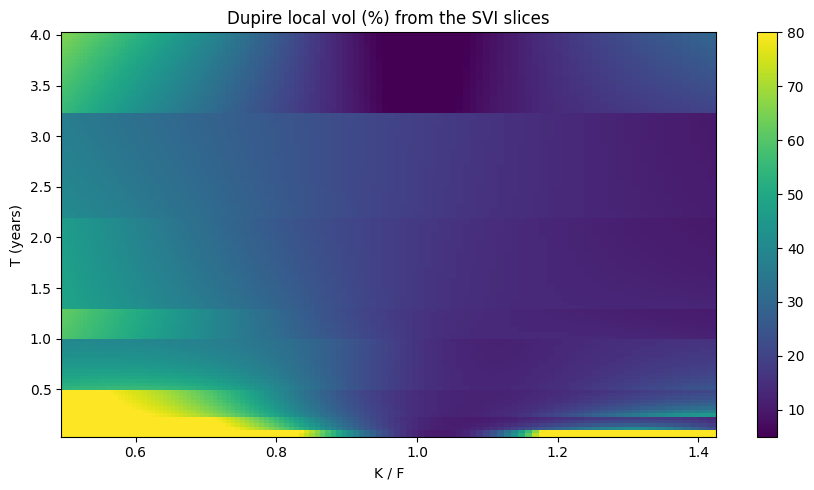

In [17]:
Fw = S0 * np.exp((cal_iv.flat_r - cal_iv.flat_q) * cal_iv.flat_T); k_all = np.log(cal_iv.flat_K / Fw); rows = {}
for name, surf in [('SSVI', SSVISurface(sorted(df_v1['T'].unique()))), ('SVI slices', SVISurface(sorted(df_v1['T'].unique())))]:
    t0 = time.perf_counter(); surf.fit(k_all, cal_iv.flat_T, cal_iv.market_iv, weights=cal_iv.quote_weights * len(cal_iv.quote_weights)); secs = time.perf_counter() - t0
    res = 100 * (surf.iv(k_all, cal_iv.flat_T) - cal_iv.market_iv); byT = pd.Series(res**2).groupby(cal_iv.flat_T).mean().pow(0.5)
    rows[name] = {'fit RMSE (vol pts)': 100 * surf.fit_rmse, 'max |err|': np.abs(res).max(), 'seconds': secs, **{f"{t:.2f}y": v for t, v in byT.items()}}
    if name == 'SVI slices': SURF = surf
SURFACES = pd.DataFrame(rows).T; display(SURFACES.round(3))
kg = np.linspace(-1.5, 0.8, 200); Wp = np.array([svi_w(kg, *p) for p in SURF.params])
print("SVI: min butterfly g(k) per slice", [round(float(svi_g(kg, *p).min()), 4) for p in SURF.params], "| min calendar gap", np.round(np.diff(Wp, axis=0).min(axis=1), 6))
kk = np.linspace(-0.7, 0.35, 120); tt = np.linspace(0.05, T_MAX, 120); KK, TT = np.meshgrid(kk, tt); LV = np.sqrt(SURF.local_var(KK.ravel(), TT.ravel())).reshape(KK.shape).clip(0.03, 1.5)
fig, ax = plt.subplots(figsize=(9, 5)); im = ax.pcolormesh(np.exp(kk), tt, 100 * LV, shading='auto', cmap='viridis', vmin=5, vmax=80); ax.set_xlabel('K / F'); ax.set_ylabel('T (years)'); ax.set_title('Dupire local vol (%) from the SVI slices'); plt.colorbar(im, ax=ax); plt.tight_layout(); plt.show()


## 16. Local vol, Heston (v1) and LSV for the note, v1 conventions

In [18]:
def vanilla_check(pricer_, label):
    rows = []
    for b in cal_iv.data_batches:
        if b['T'] > T_MAX: continue
        Ks = np.array([0.6, 0.7, 0.8, 0.9, 1.0, 1.1]) * S0; iv, se_ = mc_vanilla_iv(pricer_, b['T'], Ks, rate_curve_func, q_eff, S0)
        tg = pricer_.time_grid[pricer_._get_time_index(b['T'])]; Fm = S0 * np.exp(MU_FLAT * tg); iv_s = SURF.iv(np.log(Ks / Fm), tg)
        for K_, a_, s_ in zip(Ks, iv, iv_s): rows.append({'T': f"{b['T']:.2f}y", 'K/S0': f"{K_/S0:.0%}", 'MC - surface': 100 * (a_ - s_)})
    d = pd.DataFrame(rows).pivot(index='T', columns='K/S0', values='MC - surface'); print(f"{label}: MC implied vol minus SVI surface (RMS {np.sqrt(np.mean(d.values**2)):.2f} vol pts)"); display(d.round(2)); return float(np.sqrt(np.mean(d.values**2)))
rows = []; VAN = {}
for label, pricer_ in [('Local vol (Dupire on SVI)', LocalVolPricer(S0, S0, rate_curve_func, q_eff, PARAMS_V1, SURF, use_sv=False)), ('Heston, v1 parameters', HestonAutocallPricer(S0, S0, rate_curve_func, q_eff, PARAMS_V1, scheme='euler')),
                       ('LSV (Heston v1 + leverage)', LocalVolPricer(S0, S0, rate_curve_func, q_eff, PARAMS_V1, SURF, use_sv=True))]:
    pricer_.run_simulation(T_MAX, 252, 50000, obs_times=OBS, seed=42, verbose=False); px_ = pricer_.price_structure(**PP, pricing_date=PRICING_DATE, verbose=False); oc = pricer_.outcomes
    rows.append({'dynamics': label, 'price': px_[0], 's.e.': pricer_.std_error, 'principal': px_[1], 'coupons': px_[2], 'put': px_[3], 'P(call 1Y)': oc['call_prob_by_date'][0], 'P(KI)': oc['prob_knock_in'], 'E[level|KI]': oc['mean_perf_given_ki'], 'life': oc['expected_life']})
    VAN[label] = vanilla_check(pricer_, label)
DYN = pd.DataFrame(rows).set_index('dynamics'); DYN['vanilla RMS vs surface (vol pts)'] = pd.Series(VAN); display(DYN.round(4))
print(f"LV minus LSV (same vanillas): {DYN.loc['Local vol (Dupire on SVI)', 'price'] - DYN.loc['LSV (Heston v1 + leverage)', 'price']:+.2f} per 1,000 = dynamics (forward-skew) model risk")


Local vol (Dupire on SVI): MC implied vol minus SVI surface (RMS 0.37 vol pts)


K/S0,100%,110%,60%,70%,80%,90%
T,,,,,,
0.09y,0.02,-0.41,-1.31,-1.34,-1.06,-0.56
0.25y,0.16,-0.05,0.35,0.30,0.19,0.18
0.50y,0.09,-0.14,0.14,0.07,0.05,0.05
1.00y,0.13,-0.10,-0.09,-0.02,0.03,0.09
1.31y,0.23,-0.25,0.01,0.11,0.16,0.19
2.21y,0.13,0.15,0.11,0.15,0.16,0.12
3.22y,0.01,0.03,0.10,0.07,0.05,0.02


Heston, v1 parameters: MC implied vol minus SVI surface (RMS 3.50 vol pts)


K/S0,100%,110%,60%,70%,80%,90%
T,,,,,,
0.09y,1.78,1.28,-15.85,-12.27,-5.81,-0.22
0.25y,0.45,0.95,-6.58,-3.48,-0.80,1.03
0.50y,-0.01,-0.63,-3.06,-1.38,-0.05,0.66
1.00y,-0.56,-0.79,0.52,0.17,-0.12,-0.35
1.31y,-0.30,-0.79,-0.42,-0.31,-0.23,-0.21
2.21y,0.04,-0.07,-0.31,-0.11,0.04,0.09
3.22y,0.01,-0.01,-0.06,0.02,0.07,0.05


LSV (Heston v1 + leverage): MC implied vol minus SVI surface (RMS 0.55 vol pts)


K/S0,100%,110%,60%,70%,80%,90%
T,,,,,,
0.09y,-0.08,0.75,-2.75,-1.28,-0.87,-0.49
0.25y,-0.05,0.37,0.62,0.47,0.28,0.17
0.50y,-0.02,-0.00,0.20,0.24,0.19,0.09
1.00y,0.14,-0.02,0.28,0.25,0.21,0.15
1.31y,0.22,-0.13,0.20,0.22,0.20,0.19
2.21y,0.24,0.25,0.19,0.21,0.22,0.23
3.22y,0.15,0.16,0.22,0.21,0.19,0.16


,price,s.e.,principal,coupons,put,P(call 1Y),P(KI),E[level|KI],life,vanilla RMS vs surface (vol pts)
dynamics,,,,,,,,,,
Local vol (Dupire on SVI),962.1907,0.8797,930.8592,69.1943,-37.8627,0.6934,0.0634,0.2711,1.5444,0.3727
"Heston, v1 parameters",975.8446,0.7082,930.6471,70.8164,-25.6188,0.7112,0.0497,0.3705,1.5502,3.4964
LSV (Heston v1 + leverage),971.5623,0.7744,929.2222,72.1875,-29.8473,0.6964,0.0537,0.3207,1.5809,0.5500


LV minus LSV (same vanillas): -9.37 per 1,000 = dynamics (forward-skew) model risk


## 17. Fact table

In [19]:
facts = []
def add(section, item, value): facts.append({'section': section, 'item': item, 'value': value})
add('data', 'snapshot', f"{PRICING_DATE} EDT, spot {S0:.2f}"); add('data', 'quotes', f"{len(df_v1)} on {len(sel)} expiries (v1 rule, no filter)"); add('data', 'discount curve', RATE_SOURCE)
add('data', 'implied dividends', f"{100*df_v1['implied_q'].min():.2f}% to {100*df_v1['implied_q'].max():.2f}%, all positive")
add('calibration (v1)', 'parameters', f"kappa {PARAMS_V1[0]:.4f}, theta {PARAMS_V1[1]:.4f}, sigma {PARAMS_V1[2]:.4f}, rho {PARAMS_V1[3]:.4f}, v0 {PARAMS_V1[4]:.4f}")
add('calibration (v1)', 'Feller 2kt vs s2', f"{2*PARAMS_V1[0]*PARAMS_V1[1]:.3f} vs {PARAMS_V1[2]**2:.3f}"); add('calibration (v1)', 'price RMSE (pts, % of spot)', f"{FIT_V1['price RMSE']:.2f}, {FIT_V1['price RMSE % of spot']:.3f}%")
add('calibration (v1)', 'vol RMSE all / 1M-3M / 6M+', f"{FIT_V1['vol RMSE all']:.2f} / {FIT_V1['vol RMSE 1M-3M']:.2f} / {FIT_V1['vol RMSE 6M+']:.2f} vol pts"); add('calibration (v1)', 'product strikes mean |vol err|', f"{FIT_V1['product strikes']:.2f} vol pts")
add('price (v1)', 'fair value', f"{price:.2f} = {price/10:.2f}% (s.e. {MC_SE:.2f})"); add('price (v1)', 'legs', f"principal {p_principal:.2f}, coupons {p_coupon:.2f}, put {p_put:.2f}")
add('price (v1)', 'autocall by date', str(OUT_V1['P(call) by date'])); add('price (v1)', 'P(loss), mean level | loss, expected loss', f"{OUT_V1['P(KI)']:.1%}, {OUT_V1['E[level|KI]']:.1%}, {OUT_V1['expected loss']:.2%}")
add('price (v1)', 'expected life', f"{OUT_V1['life']:.2f} y"); add('price (v1)', 'fair coupon at par / 98.75%', f"{C_PAR:.3%} / {C_MARGIN:.3%}")
add('validation', 'martingale, vanillas, limit case', f"within ~1.5 s.e.; largest vanilla gap {VAN_MAX:.2f} s.e.; limit MC {LIM_MC:.2f} vs closed {CLOSED:.2f} vs PDE {LIM_PDE:.2f}")
add('validation', 'step / path convergence', f"{STEP_CONV['price'].round(1).tolist()} at 12/52/252 steps; {PATH_CONV['price'].round(1).tolist()} at 25k-200k paths")
add('PDE', 'price and legs', f"{PDE['total']:.2f} = {PDE['principal']:.2f} + {PDE['coupon']:.2f} {PDE['put']:+.2f}; vs MC {PDE['total']-price:+.2f} ({(PDE['total']-price)/MC_SE:+.1f} s.e.)")
add('Greeks (PDE)', 'delta hedge %, cash gamma, vega/vol pt, d/dsigma, d/drho', f"{GREEKS.loc['total','hedge % PDE']:.1f}%, {GREEKS.loc['total','cash gamma PDE']:.1f}, {GREEKS.loc['total','vega PDE']:.2f}, {GREEKS.loc['total','d/dsigma PDE']:.2f}, {GREEKS.loc['total','d/drho PDE']:.2f}")
add('rates', 'DV01 discounting / full +10bp / theta per week', f"{RATES['DV01 discounting only']:+.3f} / {RATES['full +10bp shift']:+.2f} / {THETA:+.2f}")
add('attribution', 'v1 -> v2 steps', "; ".join(f"{i}: {ATTRIB.loc[i, 'price']:.2f}" for i in ATTRIB.index))
add('objectives', 'vol RMSE all (price / vol-spread objective)', f"{OBJECTIVES.loc['price RMSE  [v1]', 'vol RMSE all']:.2f} / {OBJECTIVES.loc['vol RMSE, 1/spread^2  [v2]', 'vol RMSE all']:.2f}")
add('optimisers', 'v1 DE+LBFGS vs least_squares', f"{OPTIMISERS.loc['DE best1bin + L-BFGS-B  [v1]', 'best price RMSE']:.4f} in {OPTIMISERS.loc['DE best1bin + L-BFGS-B  [v1]', 'seconds']:.0f} s vs {OPTIMISERS.loc['least_squares (trf) from heuristic start', 'best price RMSE']:.4f} in {OPTIMISERS.loc['least_squares (trf) from heuristic start', 'seconds']:.1f} s")
for name in MODELS_TABLE.index: add('models', name, f"vol RMSE {MODELS_TABLE.loc[name, 'vol RMSE all']:.2f} / {MODELS_TABLE.loc[name, 'vol RMSE 1M-3M']:.2f} / {MODELS_TABLE.loc[name, 'vol RMSE 6M+']:.2f}; price RMSE {MODELS_TABLE.loc[name, 'price RMSE']:.1f}; product strikes {MODELS_TABLE.loc[name, 'product strikes']:.2f}")
for name in MODEL_PRICES.index: add('note by model', name, f"{MODEL_PRICES.loc[name, 'price']:.2f} (P(KI) {MODEL_PRICES.loc[name, 'P(KI)']:.1%})")
add('Feller', 'constrained fit', f"sigma {PARAMS_FELLER[2]:.2f}, vol RMSE {FELLER.iloc[1]['vol RMSE all']:.2f}, price RMSE {FELLER.iloc[1]['price RMSE']:.1f}, note {FELLER_PRICE:.2f}")
add('engines', 'Lewis FFT [v1] / Carr-Madan 1.5 / COS, max vol err', f"{ENGINES.loc['Lewis FFT + spline [v1]', 'max vol err (vol pts)']:.3f} / {ENGINES.loc['Carr-Madan FFT alpha=1.5', 'max vol err (vol pts)']:.3f} / {ENGINES.loc['COS N=256', 'max vol err (vol pts)']:.3f} vol pts")
add('expiry rule', 'nearest vs liquid, product strikes', f"{EXPIRY.iloc[0]['product strikes']:.3f} vs {EXPIRY.iloc[1]['product strikes']:.3f}")
add('Monte Carlo', 'relative efficiency', "; ".join(f"{i}: {MC.loc[i, 'relative efficiency']:.2f}" for i in MC.index))
add('surfaces', 'SSVI / SVI fit RMSE', f"{SURFACES.loc['SSVI', 'fit RMSE (vol pts)']:.2f} / {SURFACES.loc['SVI slices', 'fit RMSE (vol pts)']:.2f} vol pts")
for name in DYN.index: add('dynamics', name, f"{DYN.loc[name, 'price']:.2f} (P(KI) {DYN.loc[name, 'P(KI)']:.1%}, vanilla RMS {DYN.loc[name, 'vanilla RMS vs surface (vol pts)']:.2f})")
FACTS = pd.DataFrame(facts); pd.set_option('display.max_rows', 200); display(FACTS)
FACTS.to_csv('v1_september_facts.csv', index=False)


,section,item,value
0,data,snapshot,"2026-09-30 15:22:50.029000 EDT, spot 7696.50"
1,data,quotes,"1360 on 8 expiries (v1 rule, no filter)"
2,data,discount curve,FRED Treasury constant-maturity yield (proxy for SOFR OI...
3,data,implied dividends,"0.34% to 0.61%, all positive"
4,calibration (v1),parameters,"kappa 1.7026, theta 0.0543, sigma 1.0212, rho -0.6230, v..."
5,calibration (v1),Feller 2kt vs s2,0.185 vs 1.043
6,calibration (v1),"price RMSE (pts, % of spot)","20.81, 0.270%"
7,calibration (v1),vol RMSE all / 1M-3M / 6M+,1.66 / 2.24 / 0.99 vol pts
8,calibration (v1),product strikes mean |vol err|,0.42 vol pts
9,price (v1),fair value,975.84 = 97.58% (s.e. 0.71)


## 18. Conclusions

**The baseline.** On the September surface, v1's own method gives κ 1.70, θ 0.054, σ 1.02, ρ −0.62, v0 0.025, a price RMSE of 20.8 index points (0.27% of spot) on 1,360 unfiltered quotes, and a note value of 975.84 (s.e. 0.71): 71% autocall at year one, 87% overall, 5.0% probability of loss with a mean level of 37% given a loss, expected life 1.55 years, fair coupon 4.02% at par. The price RMSE is five times what the filtered run gives because the 4.2Y slice alone contributes 103 points: those are the stale quotes the v2 filter removes, and this notebook keeps them on purpose.

**Validation.** Martingale and vanilla-repricing checks hold within about 1.5 s.e. (the largest vanilla gap is 1.56 s.e.), Euler converges in step size (973.1 / 976.6 / 975.8) and in paths (within one s.e. from 25k to 200k), the closed-form limit case agrees (MC 988.12, closed form 988.44, PDE 988.57) and the pure bond is exact. The independent PDE prices the note at 977.46 against 975.84, 2.3 s.e. above the Monte Carlo, with the legs within 1.1; the gap is the Euler full-truncation bias with Feller violated (ratio 0.18), the QE scheme halves it (+0.47 in the attribution). Grid refinement moves the PDE by 0.2.

**Greeks.** From the PDE at inception, client seat: index hedge 15.4% of notional, cash gamma per 1% move −11.4, vega −0.90 per vol point, +1.38 per 0.1 of vol-of-vol, −0.07 per 0.1 of correlation. Monte Carlo bump-and-reprice reproduces delta and vega (16–17%, −0.78) and gets gamma only with ±3% bumps (−9.6 against −4.1 at ±1%); its vol-of-vol and correlation sensitivities on 50,000 paths are noise, including their signs. The PDE values are the reference.

**Attribution from v1 to the current pipeline.** QE +0.47, term-structure drift −0.31, 7-day payment lag −0.93, vol-space 6M+ calibration on the unfiltered quotes −1.24, the quote filter +1.59, ending at 975.43, which is `main.ipynb`'s 975.40. Rates: −0.142 per bp from discounting alone, −0.90 per 10 bp with the forward moving; theta about +1.5 per week.

**Objectives and optimisers.** On unfiltered quotes the vol-space objective still improves the vol fit (1.66 → 1.06 overall, 2.24 → 1.24 on the short end) at a cost of 2 points of price RMSE; the vega-weighted and Huber objectives give the best fit at the product strikes on clean quotes (0.19 and 0.15 against 0.23 for v1). Relative price error remains the one to avoid. All sensible optimisers reach the same optimum (20.8104); `least_squares` from the heuristic start does it in 0.3 s against 19 s for v1's DE + L-BFGS-B, and DE rand1bin and dual annealing do not reach it.

**Models.** Fitted to all eight expiries with the vol objective: Heston 1.06 vol points, Bates 0.61, double Heston 0.51, rough Heston 0.95 (its fit sits on a parameter bound, θ = 1, and is not to be trusted). The 1M slice goes from 4.2 (v1) to 2.2, 1.2 and 0.6; the 4.2Y slice is 1.8 to 1.9 for every model, the stale-quote floor. Note prices on v1 conventions: v1 Heston 976.3, Heston (vol objective) 978.5, Bates 980.2, double Heston 979.4, a 4 per 1,000 spread, about five s.e., which is larger than on the filtered data because the unfiltered long end pulls the vol-objective fits.

**Feller.** Enforced exactly through σ = s·√(2κθ) with s ≤ 1, the v1 fit collapses: σ 0.33, ρ pinned at −1, vol RMSE 5.0 (1.66 before), price RMSE 26.1, note 974.2. The COS engine polishes to the same σ, and the κ–σ ridge has its minimum at v1's point. The violation is the price of fitting the surface with a diffusion, not a defect.

**Engines, vol inversion, expiry rule, Monte Carlo.** Carr–Madan (α = 1.5) and COS cut the engine error from 0.15 points / 0.034 vol to 0.001 points / 0.0002 vol at the same cost; the two-integral form and a badly damped Carr–Madan are 40 vol points wrong in the 1M wing. Bisection with 30 iterations is exact at 2.8 ms. The liquid-expiry rule lowers the price RMSE (17.6 vs 20.8) but raises the vol RMSE, because it swaps the 1M expiry for a 7-week one with 442 quotes and a steeper skew; the product-strike fit is unchanged. On these parameters control variates give 2.1x, antithetic variates nothing, and Sobol with a Brownian bridge 2.4x (8 scrambles, so ±25% on that figure); Euler's 2.2x is cost per path, not variance.

**Dynamics.** SVI slices fit the unfiltered surface at 0.48 vol points (SSVI 1.28), with the 4.2Y slice at 1.9 from the stale quotes. Local vol reprices the surface at 0.37 vol points on its paths, LSV at 0.55, v1 Heston at 3.5 (the short end). Prices: local vol 962.2, LSV 971.6, Heston 975.8. The 9.4 per 1,000 between local vol and LSV, which share the same vanillas, is the forward-skew model risk on this note; the 4.2 between LSV and Heston is what fitting every vanilla is worth on v1's parameters.

**What this notebook settles for the presentation.** On the same data and the same conventions as the submission: the v1 numbers reproduce, the validation suite and the PDE confirm them, and every improvement in the project is quantified against them in one place. The fact table at the end (`v1_september_facts.csv`) is the source for the numbers.
